# Trabalho 1 — Previsão univariada e multivariada de séries temporais

## Comparação de arquiteturas MLP, CNN e LSTM na previsão de condições de crédito: uma abordagem de séries temporais aplicada ao estudo do risco de perda em operações bancárias

**Estudante:** Victor da Silva Araújo  
**Disciplina:** IAD-012 — Redes neurais recorrentes  
**Série:** National Financial Conditions Index (NFCI) — Federal Reserve Bank of Chicago  
**Variável-alvo:** `Credit` (Credit Subindex)  
**Frequência:** semanal  
**Repositório:** [GitHub — projeto](https://github.com/VTsilva/MLP-CNN-LSTM-estudo_risco_de_perda_em_operacoes_bancarias)  
**Fonte:** [Chicago Fed — NFCI](https://www.chicagofed.org/research/data/nfci/current-data)

---

> **Delimitação científica:** este estudo prevê o subíndice `Credit`, um indicador agregado das condições de crédito dos Estados Unidos. A motivação é o contexto de risco de crédito e provisionamento bancário; porém, o dataset não contém operações, eventos de default, exposições ou recuperações. Portanto, os modelos **não estimam diretamente PD, LGD, EAD nem provisão contábil**.

**Estado desta versão:** EDA, preparação temporal, benchmark de persistência, oito arquiteturas univariadas e oito multivariadas foram executados. Os retreinamentos e avaliações em treino, validação e teste estão consolidados. A discussão e a conclusão foram escritas em Markdown com base nos resultados efetivamente recebidos. As limitações — uma execução por arquitetura, lookback fixo e lacunas na captura do ambiente original — são explicitadas no texto.

## Sumário

1. [Contexto financeiro, regulatório e objetivo](#1-contexto-financeiro-regulatório-e-objetivo)
2. [Dados, origem e variáveis](#2-dados-origem-e-variáveis)
3. [Configuração e ingestão](#3-configuração-e-ingestão)
4. [Auditoria e preparação inicial](#4-auditoria-e-preparação-inicial)
5. [Análise exploratória da série](#5-análise-exploratória-da-série)
6. [Divisão temporal e janelas móveis](#6-divisão-temporal-e-janelas-móveis)
7. [Procedimento experimental, benchmark e métricas](#7-procedimento-experimental-benchmark-e-métricas)
8. [Experimento univariado](#8-experimento-univariado)
9. [Experimento multivariado de saída única](#9-experimento-multivariado-de-saída-única)
10. [Comparação geral e discussão final](#10-comparação-geral-e-discussão-final)
11. [Referências](#11-referências)

A narrativa parte do problema bancário de mensuração de perdas esperadas, delimita o papel de indicadores macrofinanceiros e apresenta a previsão como um experimento aplicado. As seções 10.3 e 10.4 reúnem a comparação, a discussão e a conclusão **a partir das métricas e previsões produzidas pelas execuções reais**. A conclusão é texto Markdown estático, não é criada por uma rotina de código.

## 1. Contexto financeiro, regulatório e objetivo

### 1.1 O problema bancário: risco de crédito e provisionamento

Bancos concedem crédito e assumem o risco de que parte dos tomadores não honre seus compromissos. Para refletir esse risco nas demonstrações contábeis, as instituições reconhecem provisões para perdas esperadas em instrumentos financeiros sujeitos ao risco de crédito. Esse processo é frequentemente chamado de **provisionamento**.

A **IFRS 9 — Financial Instruments** é a norma internacional que estabelece, entre outros assuntos, critérios de classificação e mensuração de instrumentos financeiros e o modelo de perdas de crédito esperadas (*Expected Credit Loss — ECL*). No Brasil, a **Resolução CMN nº 4.966/2021** estabelece critérios contábeis aplicáveis às instituições financeiras e demais instituições autorizadas pelo Banco Central abrangidas pela norma. A resolução brasileira é a referência regulatória local; não deve ser descrita como se fosse juridicamente a própria IFRS 9. A página consolidada do Banco Central consultada indica atualização em 29/08/2025 e lista, entre as alterações, a Resolução CMN nº 5.244/2025 (BANCO CENTRAL DO BRASIL, 2021; BANCO CENTRAL DO BRASIL, 2025; IFRS FOUNDATION, [s. d.]).

### 1.2 Componentes usuais na modelagem do risco de crédito

Uma decomposição didática amplamente utilizada no ecossistema de risco é:

\[
EL \approx PD \times LGD \times EAD
\]

- **PD (*Probability of Default*):** probabilidade de uma operação entrar em default em determinado horizonte.
- **LGD (*Loss Given Default*):** proporção da exposição que não se espera recuperar caso ocorra default.
- **EAD (*Exposure at Default*):** exposição estimada no momento do default.

Essa expressão é uma decomposição simplificada para explicar os componentes do risco. Ela **não substitui** a mensuração contábil completa de ECL, que considera ponderação por cenários, valor do dinheiro no tempo e informações razoáveis e sustentáveis, incluindo condições atuais e projeções prospectivas. Na Resolução CMN nº 4.966/2021, o art. 40 trata da avaliação de risco e recuperação, incluindo custos, garantias, histórico e condições econômicas; o art. 47 apresenta os estágios e horizontes de perda esperada (BANCO CENTRAL DO BRASIL, 2021).

### 1.3 Estágios de perda esperada

Na abordagem geral de impairment da IFRS 9, a mensuração varia conforme a mudança no risco de crédito desde o reconhecimento inicial:

| Estágio | Situação resumida | Base de perda esperada |
|---|---|---|
| 1 | Sem aumento significativo do risco de crédito | Perdas ao longo da vida associadas a eventos de default possíveis nos próximos 12 meses |
| 2 | Aumento significativo do risco de crédito (*SICR*), sem estar *credit-impaired* | Perdas esperadas ao longo da vida do instrumento |
| 3 | Ativo com problema de recuperação de crédito (*credit-impaired*) | Perdas esperadas ao longo da vida do instrumento |

A perda esperada de 12 meses do Estágio 1 não é simplesmente o fluxo de caixa perdido dentro dos próximos 12 meses: representa as perdas ao longo da vida do instrumento decorrentes de eventos de default possíveis nesse horizonte (IFRS FOUNDATION, 2021). A regulamentação brasileira também estabelece critérios de estágios, conforme a Resolução CMN nº 4.966/2021 (BANCO CENTRAL DO BRASIL, 2021).

### 1.4 Onde entram os modelos de Ciência de Dados

O ecossistema de provisionamento pode utilizar modelos e metodologias para PD, LGD, EAD, identificação de aumento significativo do risco de crédito (*SICR*), migração entre estágios, projeção de variáveis macroeconômicas e estimação de perdas. Entre as técnicas possíveis estão regressão logística, modelos de sobrevivência, regressões de severidade/recuperação, árvores de decisão, ensembles, modelos econométricos e redes neurais.

**As normas não prescrevem que o banco utilize MLP, CNN, LSTM ou uma arquitetura específica.** A escolha metodológica precisa ser adequada à finalidade, aos dados, à validação, à governança e aos critérios contábeis/regulatórios aplicáveis.

### 1.5 Como este dataset se conecta ao problema — e o que ele não permite concluir

O NFCI é um indicador semanal de condições financeiras dos Estados Unidos, construído a partir de 105 medidas de atividade financeira e organizado em dimensões de risco, crédito e alavancagem (CHICAGO FEDERAL RESERVE BANK, [s. d.]). Seu subíndice `Credit` resume condições nos mercados de crédito; não é taxa de inadimplência, PD, LGD ou medida de perda bancária. Séries macrofinanceiras podem contextualizar ciclos e regimes financeiros e, em estudos de risco, constituir informação complementar para cenários e projeções. Entretanto, o arquivo não contém dados de carteiras, contratos ou recuperações, tampouco representa diretamente o sistema bancário brasileiro.

Assim, este trabalho é um **experimento de previsão de condições de crédito**, motivado pelo contexto de provisionamento. Os resultados poderão ilustrar como redes neurais modelam uma série macrofinanceira relevante, mas não demonstrarão conformidade com IFRS 9/Resolução CMN 4.966 nem constituirão um modelo de provisão.

### 1.6 Objetivos e pergunta de pesquisa

**Objetivo geral:** comparar arquiteturas de redes neurais na previsão de um passo à frente do subíndice `Credit`, em experimentos univariado e multivariado.

**Pergunta de pesquisa:** como MLP, CNN e LSTM se comparam na previsão semanal de `Credit`? A inclusão dos subíndices `Risk`, `Leverage` e `Nonfinancial_Leverage` melhora a previsão em relação ao histórico exclusivo de `Credit`?

**Objetivos específicos:**
- auditar e caracterizar a qualidade e a dinâmica temporal da série;
- identificar tendências, persistência, possíveis ciclos e mudanças de regime sem inferir sazonalidade sem evidência;
- preparar janelas supervisionadas e partições cronológicas sem vazamento;
- implementar as arquiteturas exigidas no roteiro, em cenários univariado e multivariado;
- acompanhar treino e validação, selecionar épocas por inspeção e avaliar treino, validação e teste;
- comparar os modelos com um benchmark de persistência e discutir limitações.

## 2. Dados, origem e variáveis

O arquivo `data/raw/nfci-data-series-csv.csv` contém indicadores semanais do **National Financial Conditions Index (NFCI)**, calculados pelo Federal Reserve Bank of Chicago e distribuídos também pelo FRED (CHICAGO FEDERAL RESERVE BANK, [s. d.]; FEDERAL RESERVE BANK OF ST. LOUIS, [s. d.]).

- Metodologia: https://www.chicagofed.org/research/data/nfci/about
- Dados atuais: https://www.chicagofed.org/research/data/nfci/current-data
- Série `Credit` no FRED: https://fred.stlouisfed.org/series/NFCICREDIT
- Período no snapshot analisado: 08/01/1971 a 30/10/2026.
- Frequência observada: semanal, com referência às sextas-feiras.

| Coluna | Significado resumido | Papel no estudo |
|---|---|---|
| `Friday_of_Week` | Data de referência semanal | Índice temporal |
| `NFCI` | Índice agregado de condições financeiras | Não entra no primeiro desenho; sobreposição com subíndices |
| `ANFCI` | NFCI ajustado por condições macroeconômicas | Não entra no primeiro desenho; sobreposição com componentes |
| `Risk` | Condições de risco/volatilidade e financiamento | Feature candidata |
| `Credit` | Condições nos mercados de crédito | Target |
| `Leverage` | Condições de alavancagem nos segmentos financeiros | Feature candidata |
| `Nonfinancial_Leverage` | Alavancagem de famílias e empresas não financeiras | Feature candidata |

Os índices são padronizados em relação à média e ao desvio-padrão da amostra histórica de referência. Valores positivos indicam condições mais restritivas que a média; valores negativos, condições mais flexíveis. Isso não significa que um valor positivo seja uma taxa de inadimplência ou que o índice esteja expresso em percentual.

O NFCI agrega 105 medidas e é acompanhado por subíndices. A base pode ser revisada pelo produtor quando novas informações ou revisões dos componentes são incorporadas. Por reprodutibilidade, o CSV Raw deste projeto deve ser preservado como snapshot da data de download.

## 3. Configuração e ingestão

Esta etapa centraliza bibliotecas, parâmetros reprodutíveis e localização da fonte. A ingestão lê o CSV Raw sem modificar o arquivo original.

**Por que centralizar os imports?** Uma única célula de import facilita reconstruir o ambiente, conferir dependências, detectar bibliotecas desnecessárias e manter o notebook legível. As células seguintes devem utilizar objetos já importados, sem novos `import` espalhados.

In [1]:
# CÉLULA ÚNICA DE IMPORTS — manter todas as importações do notebook aqui.
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import gaussian_kde
from scipy.signal import periodogram
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

# TensorFlow é necessário para os experimentos neurais. A importação protegida
# permite executar a parte descritiva da EDA mesmo antes da instalação.
try:
    import tensorflow as tf
    TENSORFLOW_DISPONIVEL = True
    TENSORFLOW_ERRO = None
except Exception as exc:
    tf = None
    TENSORFLOW_DISPONIVEL = False
    TENSORFLOW_ERRO = repr(exc)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
if TENSORFLOW_DISPONIVEL:
    tf.keras.utils.set_random_seed(RANDOM_STATE)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")
sns.set_palette("deep")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.5f}")

print("Bibliotecas de análise carregadas.")
print(f"TensorFlow disponível: {TENSORFLOW_DISPONIVEL}")
if not TENSORFLOW_DISPONIVEL:
    print("A EDA poderá ser executada, mas o treinamento neural exige TensorFlow.")
    print("Erro identificado:", TENSORFLOW_ERRO)


Bibliotecas de análise carregadas.
TensorFlow disponível: True


In [2]:
# Localiza a raiz do projeto a partir do diretório atual.
# O notebook pode ser aberto na raiz ou em uma subpasta do repositório.
def localizar_raiz_projeto(diretorio_inicial: Path | None = None) -> Path:
    inicio = (diretorio_inicial or Path.cwd()).resolve()
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "data" / "raw" / "nfci-data-series-csv.csv").exists():
            return candidato
    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto. Abra o notebook dentro do repositório "
        "que contém data/raw/nfci-data-series-csv.csv."
    )

PROJECT_ROOT = localizar_raiz_projeto()
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "nfci-data-series-csv.csv"
RESULTADOS_DIR = PROJECT_ROOT / "resultados_execucao"
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

print("Raiz do projeto:", PROJECT_ROOT)
print("Arquivo Raw:", RAW_DATA_PATH.relative_to(PROJECT_ROOT))
print("Resultados desta execução serão salvos em:", RESULTADOS_DIR.relative_to(PROJECT_ROOT))
assert RAW_DATA_PATH.exists(), f"Arquivo não encontrado: {RAW_DATA_PATH}"


Raiz do projeto: C:\Users\vs542\Downloads\MLP-CNN-LSTM-estudo_risco_de_perda_em_operacoes_bancarias
Arquivo Raw: data\raw\nfci-data-series-csv.csv
Resultados desta execução serão salvos em: resultados_execucao


In [3]:
# Leitura do CSV original
# Friday_of_Week está armazenada no formato americano MM/DD/YYYY.

df_raw = pd.read_csv(RAW_DATA_PATH)

COLUNA_DATA = "Friday_of_Week"
TARGET = "Credit"
COLUNAS_ESPERADAS = [
    "Friday_of_Week",
    "NFCI",
    "ANFCI",
    "Risk",
    "Credit",
    "Leverage",
    "Nonfinancial_Leverage",
]

colunas_ausentes = sorted(set(COLUNAS_ESPERADAS) - set(df_raw.columns))
if colunas_ausentes:
    raise ValueError(f"Colunas esperadas ausentes no CSV: {colunas_ausentes}")

# Criar cópia de trabalho; o conteúdo de data/raw permanece intocado.
df = df_raw.copy()
df[COLUNA_DATA] = pd.to_datetime(
    df[COLUNA_DATA], format="%m/%d/%Y", errors="raise"
)
df = df.sort_values(COLUNA_DATA).set_index(COLUNA_DATA)
df.index.name = "date"

COLUNAS_NUMERICAS = df.columns.tolist()
df[COLUNAS_NUMERICAS] = df[COLUNAS_NUMERICAS].apply(pd.to_numeric, errors="raise")

print(f"Dimensão: {df.shape[0]:,} observações × {df.shape[1]} variáveis numéricas")
print(f"Período: {df.index.min():%d/%m/%Y} a {df.index.max():%d/%m/%Y}")
display(df.head())

Dimensão: 2,913 observações × 6 variáveis numéricas
Período: 08/01/1971 a 30/10/2026


,NFCI,ANFCI,Risk,Credit,Leverage,Nonfinancial_Leverage
date,,,,,,
1971-01-08,0.60500,0.58600,0.63100,-1.09000,-0.99500,-1.43400
1971-01-15,0.63800,0.64200,0.66100,-1.09100,-1.01300,-1.45100
1971-01-22,0.67600,0.71700,0.69700,-1.09300,-1.03000,-1.46600
1971-01-29,0.71700,0.80100,0.73600,-1.09800,-1.04400,-1.47900
1971-02-05,0.76000,0.88600,0.77800,-1.10500,-1.05600,-1.49000


**Resultado e consequência.** A leitura interpreta a data no padrão americano do arquivo e mantém o CSV Raw intacto. A data passa a ser índice temporal para auditar frequência e ordenar as observações. A próxima célula verifica se existem falhas que exigiriam tratamento; não imputaremos valores sem necessidade.

## 4. Auditoria e preparação inicial

A auditoria confirma tipos, ausências, duplicatas e regularidade temporal. Como a frequência original é semanal, não será feita interpolação nem preenchimento artificial sem uma evidência de lacuna que justifique esse procedimento.

In [4]:
# Auditoria da estrutura e qualidade dos dados
frequencias_intervalos = df.index.to_series().diff().dropna()
resumo_auditoria = pd.DataFrame(
    {
        "verificacao": [
            "Número de observações",
            "Número de variáveis numéricas",
            "Datas duplicadas",
            "Linhas com pelo menos um valor ausente",
            "Menor intervalo entre datas",
            "Maior intervalo entre datas",
            "Intervalos de exatamente 7 dias",
            "Período inicial",
            "Período final",
        ],
        "resultado": [
            len(df),
            df.shape[1],
            int(df.index.duplicated().sum()),
            int(df.isna().any(axis=1).sum()),
            str(frequencias_intervalos.min()),
            str(frequencias_intervalos.max()),
            int((frequencias_intervalos == pd.Timedelta(days=7)).sum()),
            df.index.min().strftime("%d/%m/%Y"),
            df.index.max().strftime("%d/%m/%Y"),
        ],
    }
)
display(resumo_auditoria)
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "valores_unicos": df.nunique()}))

# Verificações básicas que devem ser verdadeiras para esta base de trabalho.
assert len(df) >= 1000, "A série não atende ao mínimo de 1.000 observações."
assert not df.index.has_duplicates, "Há datas duplicadas. Investigue antes de prosseguir."
assert not df.isna().any().any(), "Há valores ausentes. Defina tratamento antes de prosseguir."
assert (frequencias_intervalos == pd.Timedelta(days=7)).all(), (
    "A série não possui intervalos semanais regulares de 7 dias. Investigue as lacunas."
)
assert df.index.is_monotonic_increasing, "A série não está em ordem cronológica crescente."
print("Auditoria básica concluída sem violações.")

,verificacao,resultado
0,Número de observações,2913
1,Número de variáveis numéricas,6
2,Datas duplicadas,0
3,Linhas com pelo menos um valor ausente,0
4,Menor intervalo entre datas,7 days 00:00:00
5,Maior intervalo entre datas,7 days 00:00:00
6,Intervalos de exatamente 7 dias,2912
7,Período inicial,08/01/1971
8,Período final,30/10/2026


,tipo,valores_unicos
NFCI,float64,1499
ANFCI,float64,1586
Risk,float64,1520
Credit,float64,1475
Leverage,float64,1806
Nonfinancial_Leverage,float64,1821


Auditoria básica concluída sem violações.


**Interpretação da auditoria.** Foram identificadas 2.913 observações, seis variáveis numéricas, nenhuma ausência, nenhuma data duplicada e 2.912 intervalos de exatamente sete dias, de 08/01/1971 a 30/10/2026. A série supera o mínimo de 1.000 pontos consecutivos e não requer interpolação. Isso permite avançar à EDA sem criar valores artificiais.

In [5]:
# Estatísticas descritivas das seis variáveis numéricas
display(df.describe().T.rename_axis("variavel"))

,count,mean,std,min,25%,50%,75%,max
variavel,,,,,,,,
NFCI,"2,913.00000",0.00001,1.00000,-1.09600,-0.59300,-0.38500,0.15400,5.22500
ANFCI,"2,913.00000",0.00001,1.00000,-1.33300,-0.57700,-0.38500,0.21100,5.20200
Risk,"2,913.00000",-0.00000,1.00000,-1.14700,-0.61500,-0.38600,0.19900,5.33300
Credit,"2,913.00000",0.00000,1.00000,-3.16200,-0.24300,-0.05700,0.18900,3.49300
Leverage,"2,913.00000",0.00000,0.99999,-2.01200,-0.56500,-0.14300,0.28900,3.94400
Nonfinancial_Leverage,"2,913.00000",-0.00000,1.00000,-1.97200,-0.78400,-0.14300,0.74400,2.76700


**Por que as estatísticas importam.** Médias, dispersões, quantis e extremos caracterizam a escala e a distribuição antes de definir métricas ou transformações. Os índices têm médias próximas de zero e desvios-padrão próximos de um, coerentes com a padronização histórica do produtor. Não são percentuais de inadimplência nem valores monetários. A assimetria e os extremos serão considerados na escolha de métricas e na inspeção de períodos de estresse.

## 5. Análise exploratória da série

A EDA deve identificar características observáveis, sem atribuir sazonalidade ou causalidade sem evidência. As visualizações são produzidas em escalas separadas quando as amplitudes dos índices diferem.

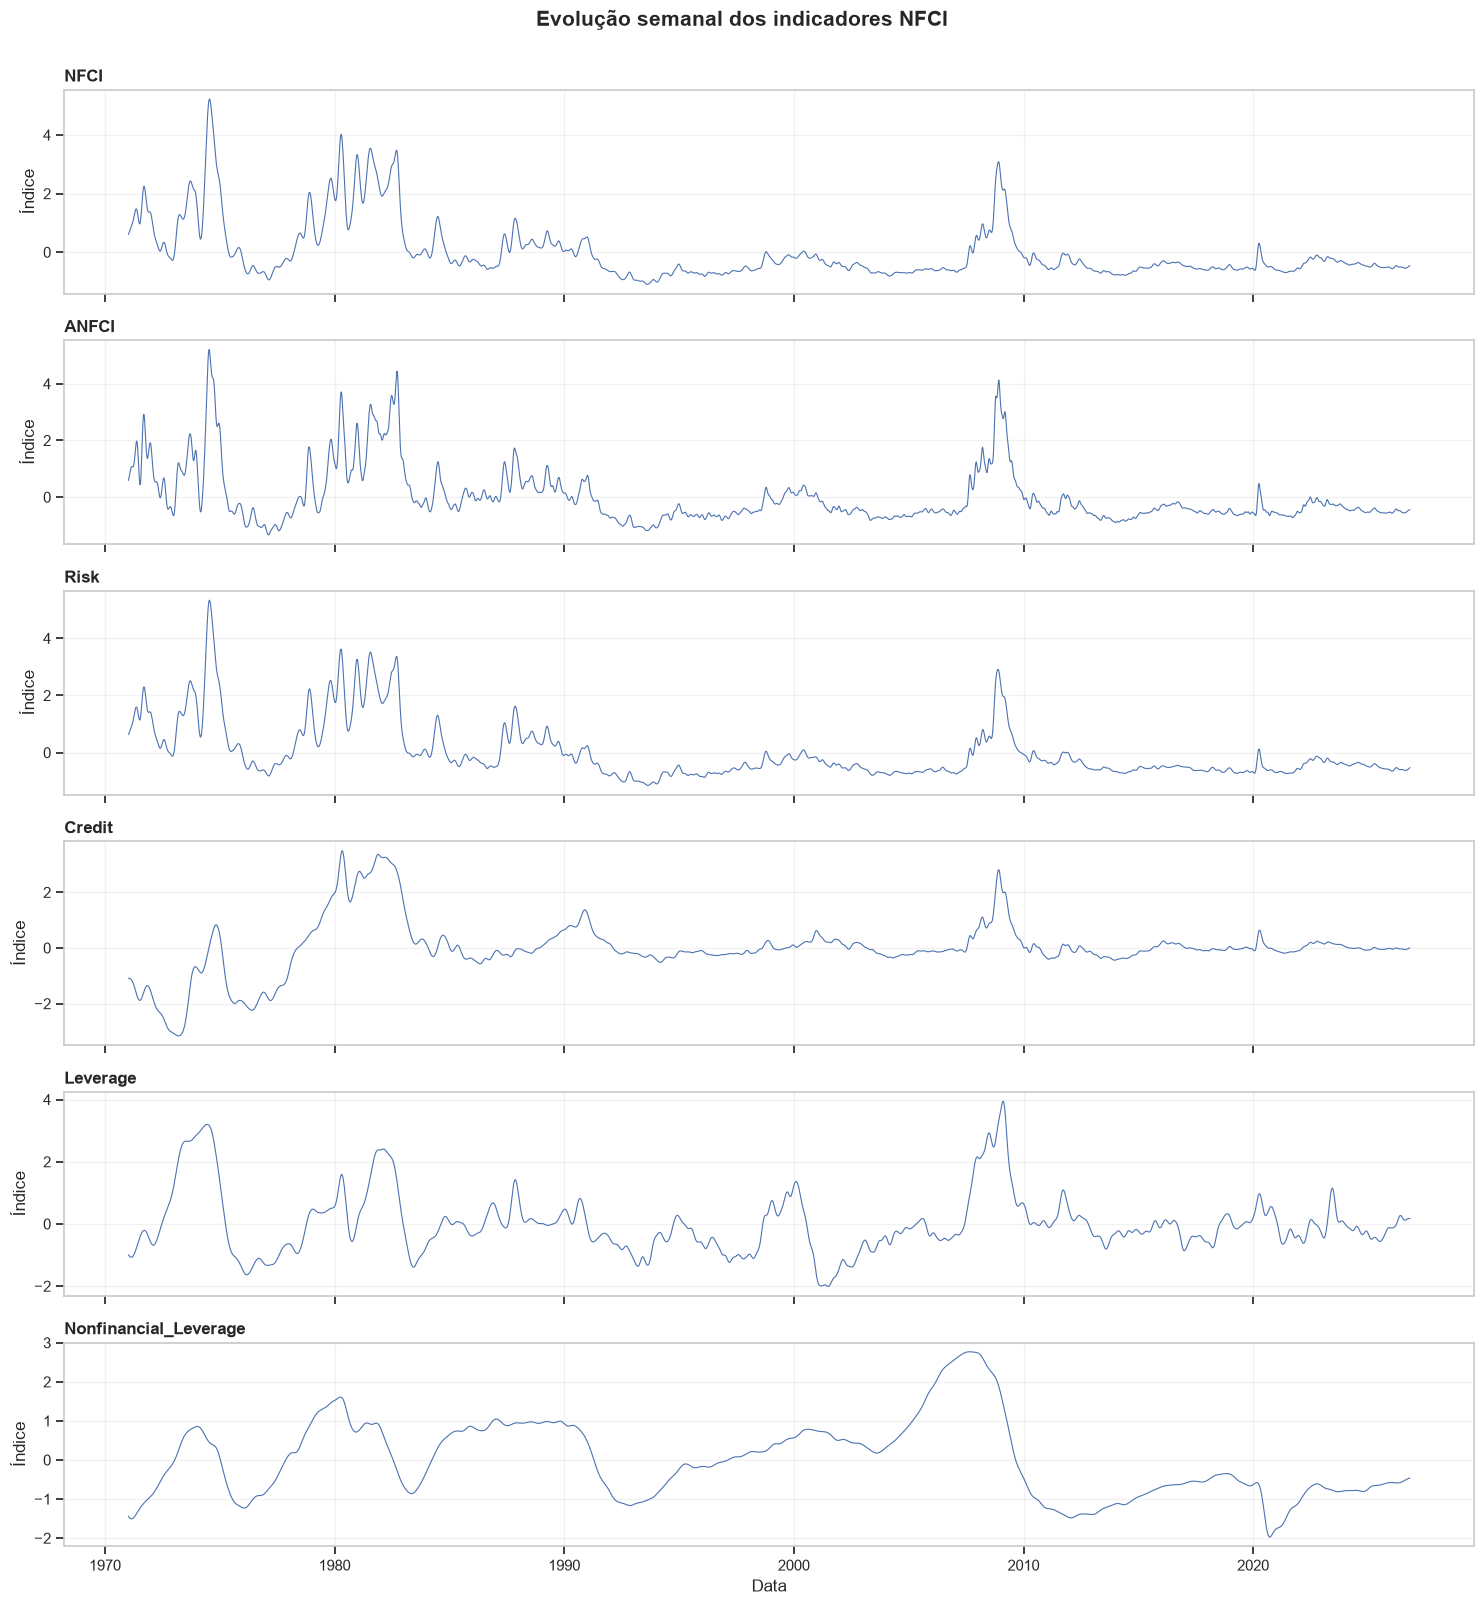

In [6]:
# Visualização individual das séries para evitar que diferenças de escala ocultem padrões.
fig, axes = plt.subplots(nrows=len(COLUNAS_NUMERICAS), ncols=1, figsize=(15, 16), sharex=True)
for ax, coluna in zip(axes, COLUNAS_NUMERICAS):
    ax.plot(df.index, df[coluna], linewidth=0.8)
    ax.set_title(coluna, loc="left", fontweight="bold")
    ax.set_ylabel("Índice")
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Data")
fig.suptitle("Evolução semanal dos indicadores NFCI", y=1.002, fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretação das trajetórias.** Os painéis separados evitam que diferenças de escala ocultem movimentos de uma variável. As séries apresentam movimentos prolongados e episódios de maior amplitude. Isso justifica manter a cronologia e avaliar estabilidade por período, além de métricas agregadas.

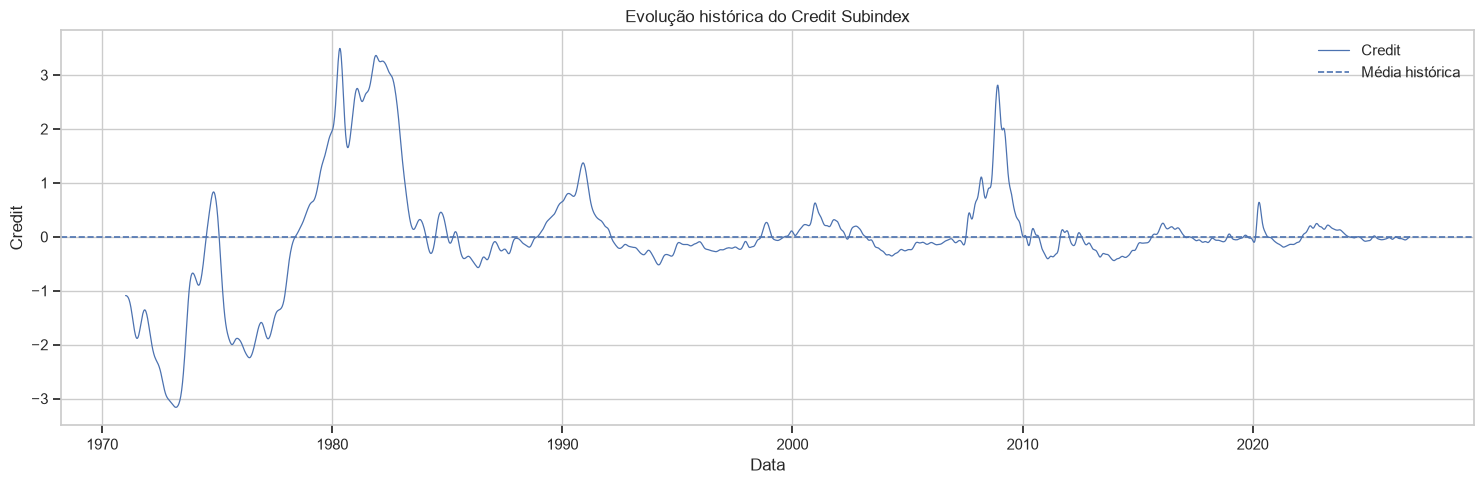

In [7]:
# Série-alvo em destaque
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df[TARGET], linewidth=0.9, label="Credit")
ax.axhline(df[TARGET].mean(), linestyle="--", linewidth=1.2, label="Média histórica")
ax.set_title("Evolução histórica do Credit Subindex")
ax.set_xlabel("Data")
ax.set_ylabel("Credit")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação do target.** `Credit` é o alvo de todas as previsões. A trajetória contém movimentos abruptos e períodos relativamente estáveis. Como a tarefa é prever apenas a semana seguinte, a informação mais recente pode ser muito forte; por isso, investigamos dependência temporal e construiremos um benchmark de persistência.

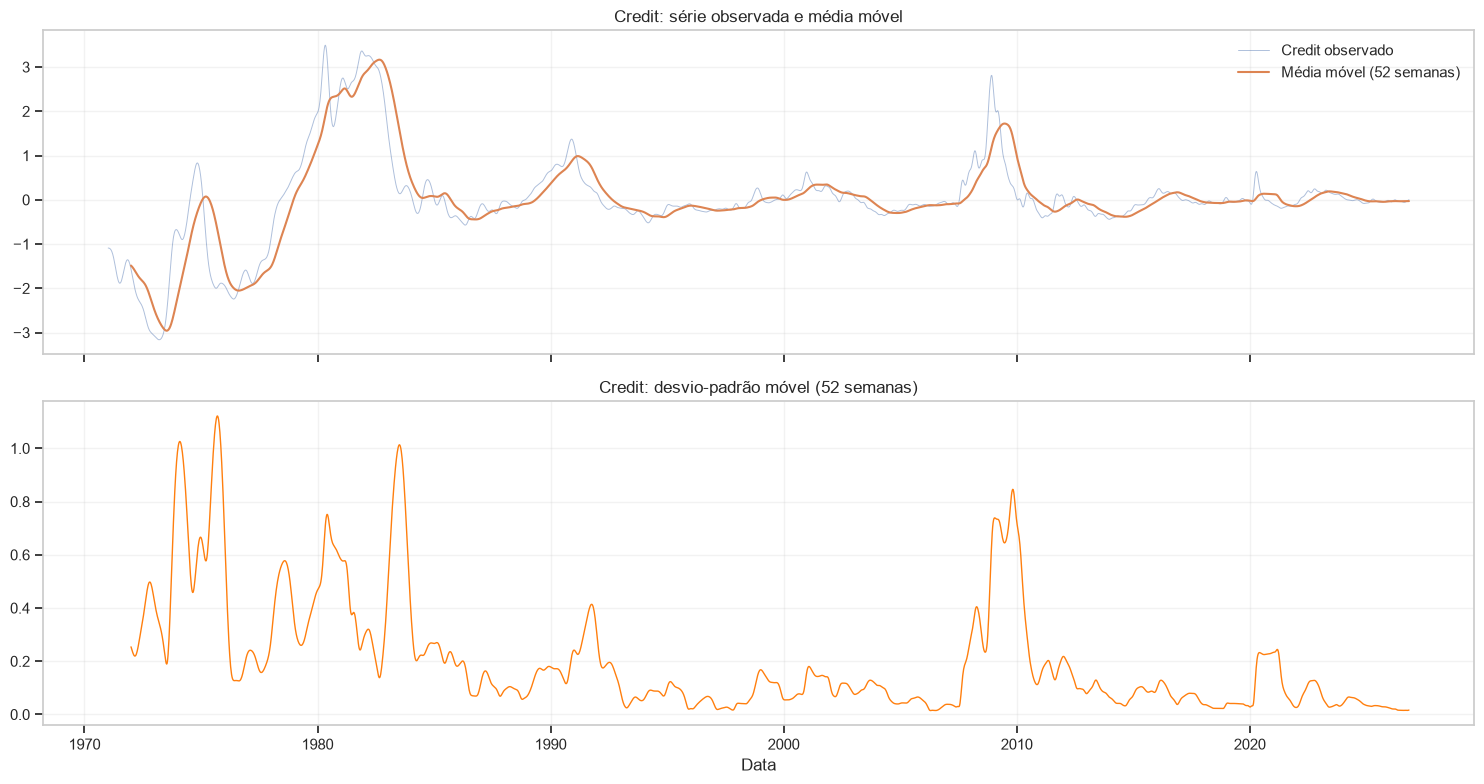

In [8]:
# Tendência local e variabilidade móvel do target.
# A janela de 52 semanas é usada aqui apenas como recurso descritivo (aproximadamente um ano),
# não como decisão do tamanho da janela de entrada dos modelos.
JANELA_DESCRITIVA = 52
credit_rolling_mean = df[TARGET].rolling(JANELA_DESCRITIVA, min_periods=JANELA_DESCRITIVA).mean()
credit_rolling_std = df[TARGET].rolling(JANELA_DESCRITIVA, min_periods=JANELA_DESCRITIVA).std()

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].plot(df.index, df[TARGET], alpha=0.45, linewidth=0.7, label="Credit observado")
axes[0].plot(df.index, credit_rolling_mean, linewidth=1.5, label="Média móvel (52 semanas)")
axes[0].set_title("Credit: série observada e média móvel")
axes[0].legend()
axes[1].plot(df.index, credit_rolling_std, linewidth=1.0, color="tab:orange")
axes[1].set_title("Credit: desvio-padrão móvel (52 semanas)")
axes[1].set_xlabel("Data")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Janela móvel descritiva.** A média móvel de 52 semanas suaviza o nível local; o desvio-padrão móvel descreve volatilidade local. O desvio-padrão móvel varia substancialmente (mediana aproximada de 0,119; máximo de 1,122 em 12/09/1975). Isso mostra heterogeneidade temporal e motiva análise de erros por regime. Esta janela é apenas descritiva e não define o lookback de entrada da rede.

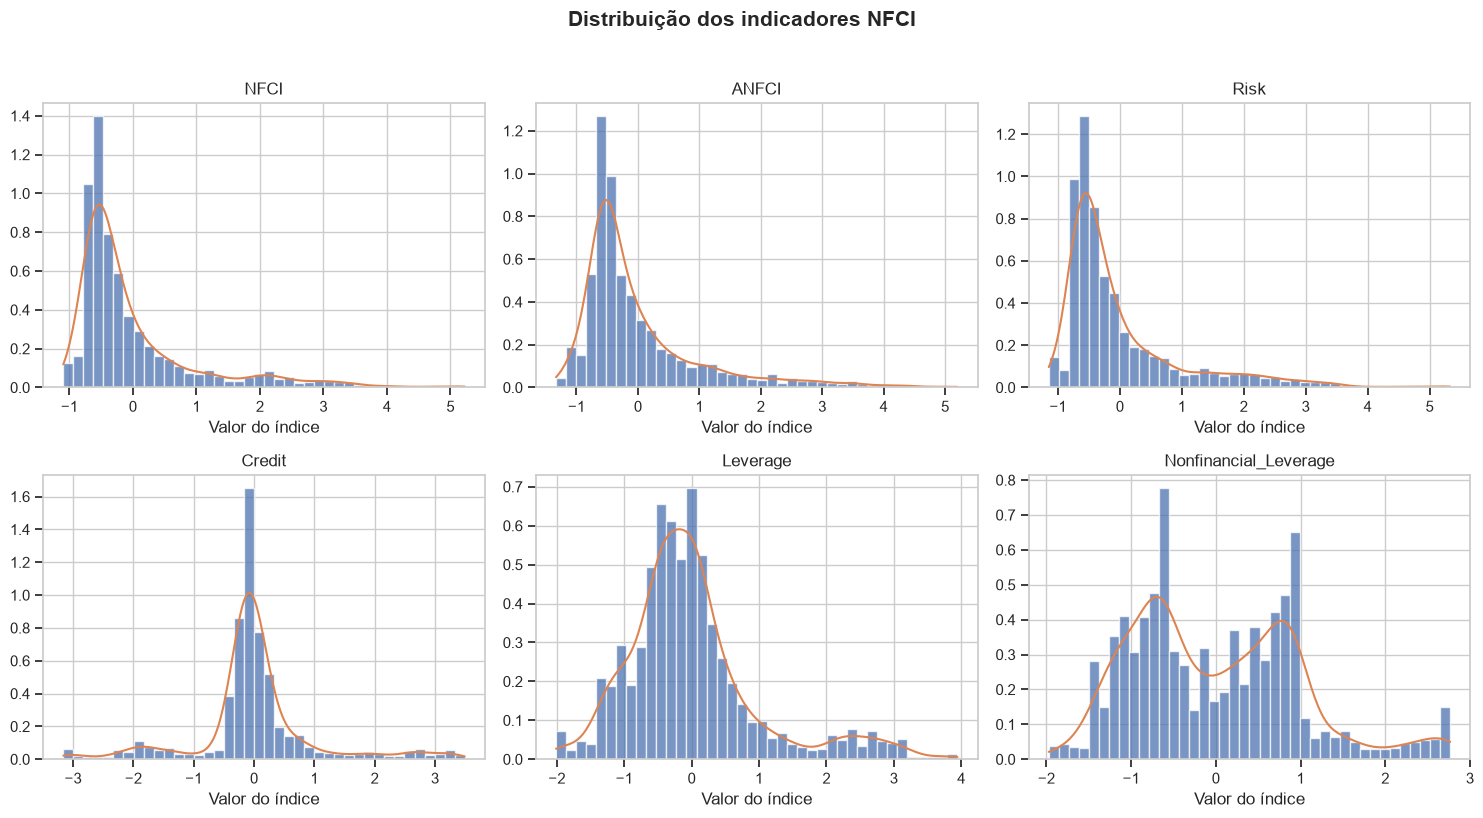

In [9]:
# Distribuições marginais das variáveis
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(axes.flat, COLUNAS_NUMERICAS):
    valores = df[coluna].dropna().to_numpy()
    ax.hist(valores, bins=40, density=True, alpha=0.75, edgecolor="white")
    # KDE calculada separadamente para evitar dependência do estimador gráfico do seaborn.
    if len(np.unique(valores)) > 1:
        grade = np.linspace(valores.min(), valores.max(), 250)
        ax.plot(grade, gaussian_kde(valores)(grade), linewidth=1.5)
    ax.set_title(coluna)
    ax.set_xlabel("Valor do índice")
fig.suptitle("Distribuição dos indicadores NFCI", y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretação das distribuições.** `Credit` apresenta assimetria aproximada de 0,435 e curtose excedente de 3,237, sugerindo assimetria positiva moderada e caudas pesadas. A combinação de MAE e RMSE será útil: MAE resume erro absoluto típico, enquanto RMSE penaliza mais os erros grandes. Também será importante examinar previsões nos episódios extremos.

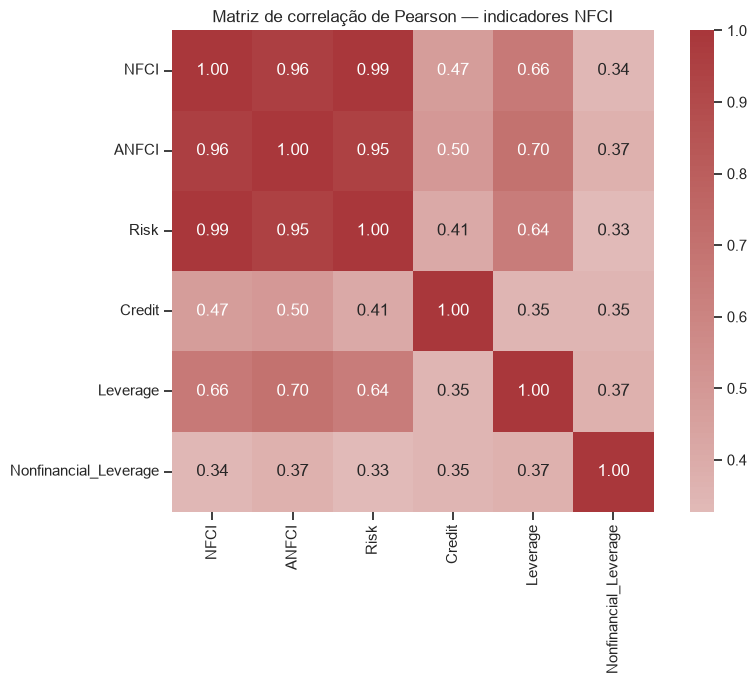

,NFCI,ANFCI,Risk,Credit,Leverage,Nonfinancial_Leverage
NFCI,1.00000,0.95633,0.99368,0.47406,0.66205,0.33876
ANFCI,0.95633,1.00000,0.94711,0.49786,0.69929,0.37284
Risk,0.99368,0.94711,1.00000,0.40954,0.64280,0.32744
Credit,0.47406,0.49786,0.40954,1.00000,0.35202,0.34997
Leverage,0.66205,0.69929,0.64280,0.35202,1.00000,0.37198
Nonfinancial_Leverage,0.33876,0.37284,0.32744,0.34997,0.37198,1.00000


In [10]:
# Correlação contemporânea: útil para descrever associação, não causalidade nem precedência temporal.
matriz_correlacao = df.corr(method="pearson")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Matriz de correlação de Pearson — indicadores NFCI")
plt.tight_layout()
plt.show()
display(matriz_correlacao)

**Interpretação da correlação contemporânea.** `Credit` correlaciona-se aproximadamente 0,4095 com `Risk`, 0,3520 com `Leverage` e 0,3500 com `Nonfinancial_Leverage`. `NFCI` apresenta correlação muito alta com `Risk` (aprox. 0,994), e índices agregados compartilham informação com seus componentes. Por isso, `NFCI` e `ANFCI` ficam fora do primeiro desenho multivariado. Correlação simultânea não prova ganho preditivo; a próxima célula alinha variáveis em `t` ao target em `t+1`.

**Pergunta seguinte.** As variáveis associadas a `Credit` na mesma semana também estão associadas ao valor da semana seguinte? Esta análise de correlação defasada é uma triagem, não uma prova de causalidade ou de ganho preditivo.

In [11]:
# Associação temporal simples: variáveis observadas em t versus Credit em t+1.
# É uma triagem preditiva exploratória, não teste causal nem evidência suficiente para selecionar features.
variaveis_lagged = ["Credit", "Risk", "Leverage", "Nonfinancial_Leverage", "NFCI", "ANFCI"]
linhas_lagged = []
for variavel in variaveis_lagged:
    x_t = df[variavel].iloc[:-1].reset_index(drop=True)
    y_t1 = df[TARGET].iloc[1:].reset_index(drop=True)
    linhas_lagged.append({"variavel_em_t": variavel, "correlacao_com_Credit_t_mais_1": x_t.corr(y_t1)})
tabela_correlacoes_defasadas = pd.DataFrame(linhas_lagged).sort_values(
    "correlacao_com_Credit_t_mais_1", ascending=False
)
display(tabela_correlacoes_defasadas)

,variavel_em_t,correlacao_com_Credit_t_mais_1
0,Credit,0.99954
5,ANFCI,0.50052
4,NFCI,0.47849
1,Risk,0.41438
2,Leverage,0.35651
3,Nonfinancial_Leverage,0.35581


**Interpretação das correlações defasadas.** O histórico de `Credit` em `t` tem correlação aproximada de 0,9995 com `Credit` em `t+1`. `Risk`, `Leverage` e `Nonfinancial_Leverage` mostram associações positivas menores (aprox. 0,414; 0,357; 0,356). Isso justifica investigar sua contribuição no multivariado, mas não prova que melhorem a previsão. A decisão virá do desempenho na validação comparado ao univariado.

### 5.3 Dependência temporal: ACF e PACF

**Pergunta:** até que ponto os valores passados de `Credit` estão associados ao valor atual? A ACF resume a associação com defasagens; a PACF ajuda a avaliar a contribuição de um lag após controlar os lags intermediários. Como a periodicidade é semanal, cada lag corresponde a uma semana. O resultado orientará a escolha de candidatos de lookback e a necessidade de um benchmark simples.

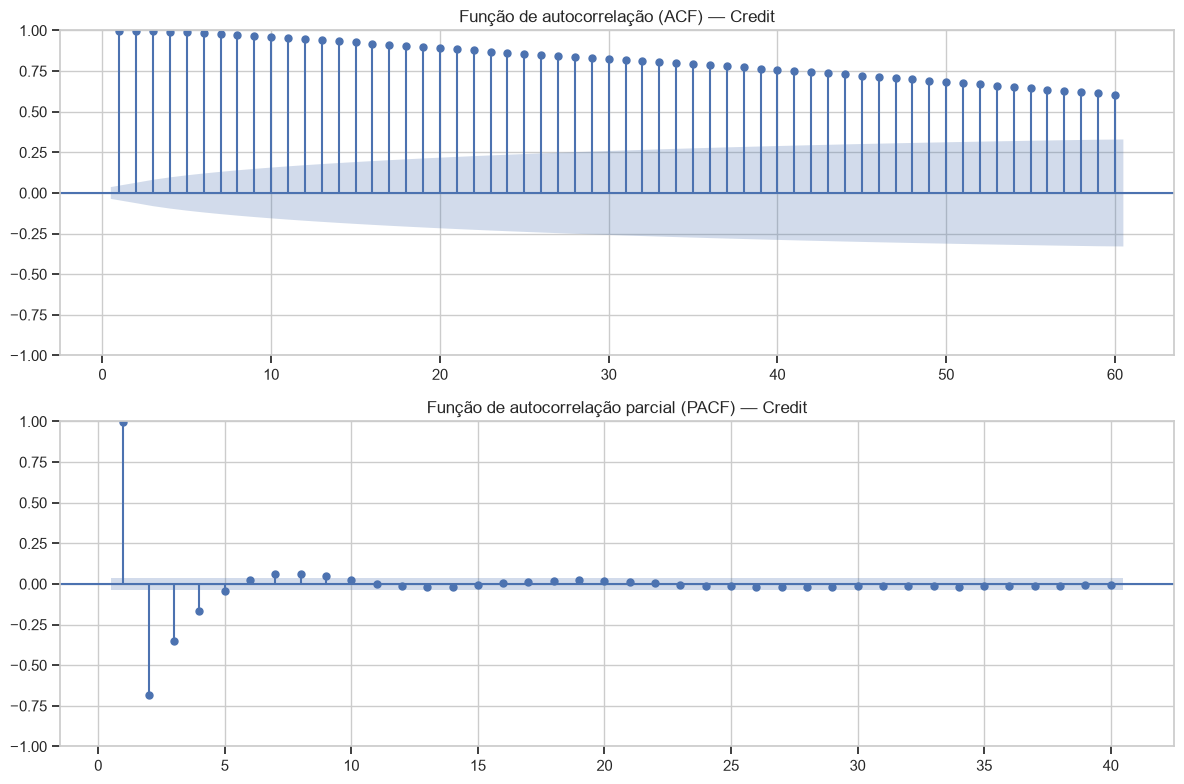

In [12]:
# Autocorrelação e autocorrelação parcial do target.
# Os lags representam semanas, pois a série possui frequência semanal regular.

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(df[TARGET], lags=60, ax=axes[0], zero=False)
axes[0].set_title("Função de autocorrelação (ACF) — Credit")
plot_pacf(df[TARGET], lags=40, method="ywm", ax=axes[1], zero=False)
axes[1].set_title("Função de autocorrelação parcial (PACF) — Credit")
plt.tight_layout()
plt.show()

**Interpretação da ACF/PACF.** A ACF de `Credit` permanece elevada: aproximadamente 0,9995 no lag 1, 0,6826 no lag 52 e 0,3520 no lag 104. Isso indica persistência de longo alcance e sugere que janelas históricas relativamente amplas podem carregar informação útil. Entretanto, ACF elevada não determina por si só o comprimento ótimo da entrada. Para manter a comparação das 16 arquiteturas controlada, o estudo adota 52 semanas como lookback operacional fixo; 13, 26 e 104 semanas não foram comparadas quanto ao desempenho preditivo. O benchmark de persistência é indispensável justamente porque o último valor observado já contém forte informação sobre o seguinte.

### 5.4 Frequências dominantes e hipótese de ciclos

**Pergunta:** existem frequências dominantes que justifiquem falar em ciclos ou sazonalidade? O periodograma decompõe a potência da série por frequência. Nesta base semanal, os períodos serão interpretados em semanas. Picos são evidência exploratória; não provam por si só um ciclo estável ou sazonalidade.

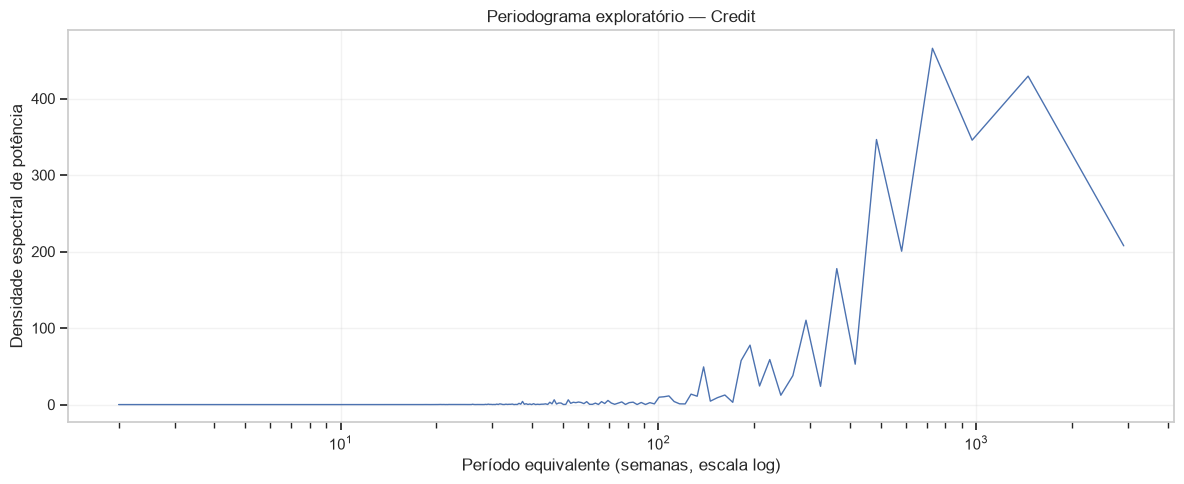

In [13]:
# Periodograma exploratório do target para investigar frequências dominantes.
# A identificação de picos não basta, isoladamente, para afirmar sazonalidade.

frequencias, potencia = periodogram(df[TARGET].to_numpy(), fs=1.0, detrend="linear")
mask = frequencias > 0
periodos_semanas = 1 / frequencias[mask]
potencia_sem_zero = potencia[mask]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(periodos_semanas, potencia_sem_zero, linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Período equivalente (semanas, escala log)")
ax.set_ylabel("Densidade espectral de potência")
ax.set_title("Periodograma exploratório — Credit")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretação do periodograma.** A potência concentra-se em frequências baixas, correspondentes a oscilações plurianuais. Os picos não comprovam ciclos regulares e não sustentam afirmar sazonalidade anual de 52 semanas. A janela de 52 será testada como contexto operacional, lado a lado com outras durações.

### 5.5 Estacionariedade: testes complementares

**Pergunta:** os dados fornecem evidência compatível com estacionariedade em nível? O ADF tem como hipótese nula a existência de raiz unitária; o KPSS tem como hipótese nula a estacionariedade. Os testes são executados na amostra completa para descrição e no bloco de treino para apoiar decisões de modelagem. A validação e o teste não devem orientar transformações.

In [14]:
# ADF e KPSS são testes complementares com hipóteses nulas diferentes.
# A amostra completa é descritiva; a decisão de transformação deve considerar somente o treino.
def executar_testes_estacionariedade(serie, nome_amostra):
    serie = pd.Series(serie).dropna()
    resultado_adf = adfuller(serie, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        resultado_kpss = kpss(serie, regression="c", nlags="auto")
    return {
        "amostra": nome_amostra,
        "n": len(serie),
        "ADF_estatistica": resultado_adf[0],
        "ADF_pvalor": resultado_adf[1],
        "KPSS_estatistica": resultado_kpss[0],
        "KPSS_pvalor": resultado_kpss[1],
    }

serie_credit = df[TARGET].dropna()
limite_treino_eda = int(np.floor(0.70 * len(serie_credit)))
resultados_estacionariedade = pd.DataFrame([
    executar_testes_estacionariedade(serie_credit, "Amostra completa — descritiva"),
    executar_testes_estacionariedade(serie_credit.iloc[:limite_treino_eda], "Treinamento — decisões de modelagem"),
])
display(resultados_estacionariedade)
print("ADF: H0 = raiz unitária. KPSS: H0 = estacionariedade em nível.")
print("Interprete ambos: evidências divergentes podem refletir quebras estruturais, regimes ou sensibilidade da amostra.")

C:\Users\vs542\AppData\Local\Temp\ipykernel_9368\739382632.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie, autolag="AIC")
C:\Users\vs542\AppData\Local\Temp\ipykernel_9368\739382632.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie, autolag="AIC")


,amostra,n,ADF_estatistica,ADF_pvalor,KPSS_estatistica,KPSS_pvalor
0,Amostra completa — descritiva,2913,-3.62433,0.00531,0.39941,0.07741
1,Treinamento — decisões de modelagem,2039,-3.12101,0.02504,0.68575,0.01484


ADF: H0 = raiz unitária. KPSS: H0 = estacionariedade em nível.
Interprete ambos: evidências divergentes podem refletir quebras estruturais, regimes ou sensibilidade da amostra.


**Interpretação dos testes.** Na amostra completa, ADF p≈0,0053 rejeita raiz unitária e KPSS p≈0,0774 não rejeita estacionariedade a 5%. No treino, ADF p≈0,0250 rejeita raiz unitária, mas KPSS p≈0,0148 rejeita estacionariedade. As evidências dependem do período e das hipóteses dos testes; isso pode refletir quebras/regimes e não deve ser simplificado para uma conclusão binária. Consequência: manter a série em nível no baseline e não diferenciar automaticamente; qualquer transformação alternativa deverá ser ajustada no treino e selecionada pela validação.

### 5.1 Síntese crítica da EDA e decisões decorrentes

A EDA indica que o arquivo tem 2.913 observações semanais regulares e completas. A variável `Credit` é altamente persistente: a ACF é aproximadamente 0,9995 no lag 1, 0,6826 no lag 52 e 0,3520 no lag 104. Isso justifica testar modelos capazes de utilizar sequências, mas também indica que a previsão ingênua pelo último valor pode ser um benchmark muito competitivo.

As correlações contemporâneas de `Credit` com `Risk`, `Leverage` e `Nonfinancial_Leverage` são positivas e moderadas (aproximadamente 0,410; 0,352; 0,350). A correlação contemporânea não demonstra precedência nem ganho de previsão. Na triagem defasada, a correlação de `Credit[t]` com `Credit[t+1]` foi aproximadamente 0,99954; para `Risk`, `Leverage` e `Nonfinancial_Leverage`, os valores foram 0,41438, 0,35651 e 0,35581, respectivamente. Esses números indicam associação temporal muito mais forte do próprio histórico de `Credit`, mas não demonstram informação incremental das outras variáveis. O critério decisivo continua sendo o desempenho preditivo na validação — e os resultados finais multivariados não superaram a persistência.

A volatilidade móvel varia ao longo do tempo, e a distribuição de `Credit` apresenta assimetria positiva moderada e caudas mais pesadas que a normal. O periodograma concentra potência em frequências baixas, sem evidência suficiente para afirmar sazonalidade anual. Os testes ADF/KPSS são complementares e dão sinais diferentes dependendo de usar a amostra completa ou somente o treino. Não será aplicada diferenciação automaticamente.

**Consequências para as etapas seguintes:** (1) preservar a previsão em nível como baseline; (2) usar divisão cronológica e escalonadores ajustados somente no treino; (3) manter lookback de 52 semanas como escolha operacional comum, sem alegar otimalidade; (4) avaliar cada arquitetura contra persistência; (5) analisar os erros à luz da volatilidade de cada partição. A sensibilidade de desempenho a 13, 26 e 104 semanas fica como extensão futura e deve ser selecionada exclusivamente por validação.

## 6. Divisão temporal e construção de janelas supervisionadas

A série será particionada **antes** de qualquer embaralhamento: 70% iniciais para treinamento, 20% seguintes para validação e 10% finais para teste. O conjunto de teste permanecerá reservado até a avaliação final.

O problema é de previsão de **um passo à frente**: uma janela com `WINDOW_SIZE` observações históricas termina em `t` e prevê exclusivamente `Credit` em `t+1`. Para validação e teste, as janelas podem utilizar o passado já observado em partições anteriores, mas cada alvo permanece em sua partição. Essa estratégia simula uma previsão semanal atualizada à medida que novos valores observados ficam disponíveis.

O escalonamento será ajustado somente no bloco de treinamento. Os parâmetros aprendidos no treino serão aplicados sem reajuste à validação e ao teste.


In [15]:
# Particionamento cronológico 70% / 20% / 10%
N_OBSERVACOES = len(df)
TRAIN_END = int(np.floor(0.70 * N_OBSERVACOES))
VALIDATION_END = int(np.floor(0.90 * N_OBSERVACOES))

train_df = df.iloc[:TRAIN_END].copy()
validation_df = df.iloc[TRAIN_END:VALIDATION_END].copy()
test_df = df.iloc[VALIDATION_END:].copy()

resumo_particoes = pd.DataFrame(
    [
        {"conjunto": "Treinamento", "inicio": train_df.index.min(), "fim": train_df.index.max(), "observacoes": len(train_df)},
        {"conjunto": "Validação", "inicio": validation_df.index.min(), "fim": validation_df.index.max(), "observacoes": len(validation_df)},
        {"conjunto": "Teste", "inicio": test_df.index.min(), "fim": test_df.index.max(), "observacoes": len(test_df)},
    ]
)
display(resumo_particoes)
assert len(train_df) + len(validation_df) + len(test_df) == N_OBSERVACOES

,conjunto,inicio,fim,observacoes
0,Treinamento,1971-01-08,2010-01-29,2039
1,Validação,2010-02-05,2021-03-26,582
2,Teste,2021-04-02,2026-10-30,292


**Interpretação da divisão.** A separação cronológica resulta em 2.039 observações de treino (08/01/1971–29/01/2010), 582 de validação (05/02/2010–26/03/2021) e 292 de teste (02/04/2021–30/10/2026). Os períodos têm condições econômicas distintas; métricas entre partições devem ser lidas considerando volatilidade e regimes. O teste fica reservado à avaliação final.

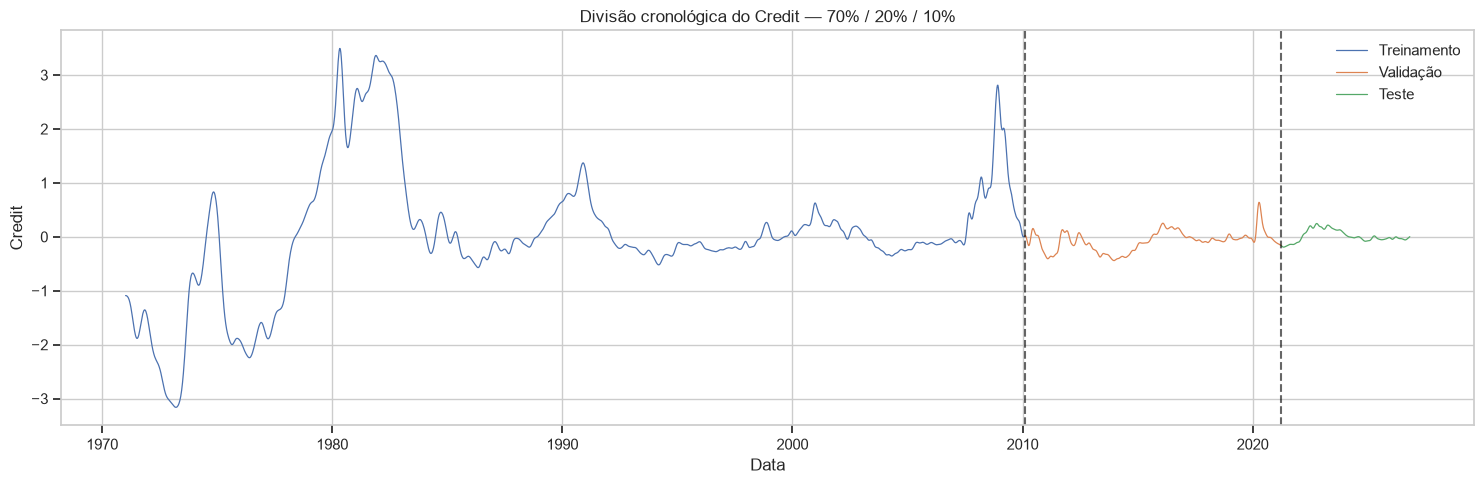

In [16]:
# Visualização dos três segmentos cronológicos
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(train_df.index, train_df[TARGET], label="Treinamento", linewidth=0.9)
ax.plot(validation_df.index, validation_df[TARGET], label="Validação", linewidth=0.9)
ax.plot(test_df.index, test_df[TARGET], label="Teste", linewidth=0.9)
ax.axvline(validation_df.index.min(), color="black", linestyle="--", alpha=0.6)
ax.axvline(test_df.index.min(), color="black", linestyle="--", alpha=0.6)
ax.set_title("Divisão cronológica do Credit — 70% / 20% / 10%")
ax.set_xlabel("Data")
ax.set_ylabel("Credit")
ax.legend()
plt.tight_layout()
plt.show()

**Por que visualizar os cortes?** O gráfico confirma que não houve embaralhamento antes da partição e torna explícitos os regimes históricos atribuídos a cada conjunto. A validação e o teste pertencem a períodos posteriores ao treino; portanto, medem generalização temporal, não uma amostra aleatória da mesma distribuição.

### 6.1 Janela descritiva e *lookback*: conceitos diferentes

Uma **janela descritiva** é usada para resumir o comportamento recente da série. Por exemplo, média móvel e desvio-padrão móvel de 52 semanas ajudam a observar o nível e a volatilidade locais. Ela gera estatísticas para interpretação e não define, por si só, a entrada supervisionada do modelo.

O **lookback** é a quantidade de observações anteriores que o modelo recebe para prever o próximo valor. Com `lookback = 52`, a entrada é formada pelas 52 semanas anteriores e o alvo é somente o `Credit` da semana seguinte.

**Por que 52 semanas como baseline?** A frequência é semanal, portanto 52 observações representam aproximadamente um ano de histórico. A ACF ainda apresenta associação relevante no lag 52, o que torna esse horizonte um candidato razoável para fornecer contexto temporal mais amplo. Isso **não comprova sazonalidade anual** nem significa que 52 seja o lookback ótimo. Janelas menores (13 e 26) privilegiam contexto mais recente; uma janela maior (104) amplia o histórico, mas pode carregar informação antiga e reduzir as amostras iniciais disponíveis para treino.

Para manter a comparação das 16 arquiteturas controlada e executável, o experimento principal utilizará 52 semanas em todos os modelos. Esse valor será tratado como **baseline experimental**, não como resultado de uma otimização exaustiva. A sensibilidade a outros lookbacks poderá ser estudada depois, mantendo a validação como critério de seleção e sem consultar o teste.


In [ ]:
# Escolha operacional fixa para comparar as arquiteturas sob a mesma entrada.
# 52 observações semanais representam aproximadamente um ano de contexto; não é uma janela otimizada.
WINDOW_SIZE = 52
CANDIDATOS_JANELA = [13, 26, 52, 104]  # apenas para ilustrar custo amostral na tabela seguinte
print(f"Lookback operacional fixo: {WINDOW_SIZE} semanas; não foi realizada otimização por validação.")


**Decisão metodológica — lookback fixo de 52 semanas.** O valor de 52 foi mantido em todas as arquiteturas para padronizar a comparação entre modelos e fornecer aproximadamente um ano de contexto semanal. A tabela abaixo tem finalidade exclusivamente descritiva: mostra como o número de janelas disponíveis muda com diferentes comprimentos; ela **não** representa uma comparação de desempenho preditivo. Neste trabalho, 52 semanas é uma escolha operacional, não um ótimo demonstrado por validação e não evidência de sazonalidade anual.


In [18]:
# Quantificar a redução de amostras ao aumentar o lookback.
# O número de targets de validação/teste é preservado; suas janelas podem usar contexto anterior disponível.
linhas_janelas = []
for lookback in CANDIDATOS_JANELA:
    linhas_janelas.append({
        "lookback_semanas": lookback,
        "aproximacao": {13: "3 meses", 26: "6 meses", 52: "1 ano", 104: "2 anos"}[lookback],
        "amostras_treino": TRAIN_END - lookback,
        "amostras_validacao": VALIDATION_END - TRAIN_END,
        "amostras_teste": N_OBSERVACOES - VALIDATION_END,
    })
tabela_candidatos_janela = pd.DataFrame(linhas_janelas)
display(tabela_candidatos_janela)

,lookback_semanas,aproximacao,amostras_treino,amostras_validacao,amostras_teste
0,13,3 meses,2026,582,292
1,26,6 meses,2013,582,292
2,52,1 ano,1987,582,292
3,104,2 anos,1935,582,292


**Interpretação.** A tabela quantifica somente o efeito amostral de diferentes comprimentos. Nenhum modelo foi treinado com lookbacks de 13, 26 ou 104 semanas; logo, não há resultado que permita afirmar qual janela teria menor erro. Para o escopo deste trabalho, 52 semanas permanece fixa em todos os experimentos para isolar a comparação entre arquiteturas. Uma análise de sensibilidade por lookback fica como possibilidade de pesquisa futura e deverá selecionar a janela exclusivamente pela validação, sem consultar o teste.


In [19]:
# Funções reutilizáveis para criar janelas supervisionadas sem quebrar a cronologia.


def criar_janelas_supervisionadas(
    features_escaladas: np.ndarray,
    target_escalado: np.ndarray,
    lookback: int,
    inicio_target: int,
    fim_target: int,
):
    """Cria X[t-lookback:t] -> y[t] para índices-alvo em [inicio_target, fim_target)."""
    if lookback <= 0:
        raise ValueError("lookback deve ser positivo.")
    if inicio_target < lookback:
        raise ValueError("O início dos alvos precisa permitir uma janela histórica completa.")
    if fim_target > len(features_escaladas) or fim_target > len(target_escalado):
        raise ValueError("fim_target excede o tamanho dos dados.")

    X, y, indices_alvo = [], [], []
    for indice in range(inicio_target, fim_target):
        X.append(features_escaladas[indice - lookback:indice])
        y.append(target_escalado[indice])
        indices_alvo.append(indice)

    return np.asarray(X), np.asarray(y).reshape(-1, 1), np.asarray(indices_alvo)


def preparar_particoes_janeladas(
    dataframe: pd.DataFrame,
    features: list[str],
    target: str,
    lookback: int,
    train_end: int,
    validation_end: int,
):
    """Ajusta escalonadores somente no treino e cria alvos dentro de cada partição.

    As primeiras janelas de validação/teste podem usar observações históricas de
    partições anteriores, pois elas já seriam conhecidas no instante da previsão.
    Nenhum alvo de validação/teste entra no ajuste dos escalonadores.
    """
    if target not in features:
        warnings.warn("O histórico do target não está nas features de entrada.", UserWarning)

    X_original = dataframe[features].to_numpy(dtype=float)
    y_original = dataframe[target].to_numpy(dtype=float).reshape(-1, 1)

    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    scaler_X.fit(X_original[:train_end])
    scaler_y.fit(y_original[:train_end])

    X_escalado = scaler_X.transform(X_original)
    y_escalado = scaler_y.transform(y_original).ravel()

    X_train, y_train, idx_train = criar_janelas_supervisionadas(
        X_escalado, y_escalado, lookback, lookback, train_end
    )
    X_val, y_val, idx_val = criar_janelas_supervisionadas(
        X_escalado, y_escalado, lookback, train_end, validation_end
    )
    X_test, y_test, idx_test = criar_janelas_supervisionadas(
        X_escalado, y_escalado, lookback, validation_end, len(dataframe)
    )

    return {
        "X_train": X_train, "y_train": y_train, "idx_train": idx_train,
        "X_val": X_val, "y_val": y_val, "idx_val": idx_val,
        "X_test": X_test, "y_test": y_test, "idx_test": idx_test,
        "scaler_X": scaler_X, "scaler_y": scaler_y,
        "y_original": y_original.ravel(),
    }

print(f"Funções de janelamento definidas. Lookback baseline ativo: {WINDOW_SIZE} semanas.")

Funções de janelamento definidas. Lookback baseline ativo: 52 semanas.


In [20]:
# Preparar os dois conjuntos de entrada com o mesmo lookback e os mesmos cortes cronológicos.
FEATURES_UNIVARIATE = ["Credit"]
FEATURES_MULTIVARIATE = ["Credit", "Risk", "Leverage", "Nonfinancial_Leverage"]

# O histórico de Credit entra como feature defasada; o único target continua sendo Credit[t+1].
dados_univariados = preparar_particoes_janeladas(
    dataframe=df,
    features=FEATURES_UNIVARIATE,
    target=TARGET,
    lookback=WINDOW_SIZE,
    train_end=TRAIN_END,
    validation_end=VALIDATION_END,
)

dados_multivariados = preparar_particoes_janeladas(
    dataframe=df,
    features=FEATURES_MULTIVARIATE,
    target=TARGET,
    lookback=WINDOW_SIZE,
    train_end=TRAIN_END,
    validation_end=VALIDATION_END,
)

print("Shapes univariados:", dados_univariados["X_train"].shape,
      dados_univariados["X_val"].shape, dados_univariados["X_test"].shape)
print("Shapes multivariados:", dados_multivariados["X_train"].shape,
      dados_multivariados["X_val"].shape, dados_multivariados["X_test"].shape)
assert dados_univariados["idx_train"].tolist() == dados_multivariados["idx_train"].tolist()
assert dados_univariados["idx_val"].tolist() == dados_multivariados["idx_val"].tolist()
assert dados_univariados["idx_test"].tolist() == dados_multivariados["idx_test"].tolist()


Shapes univariados: (1987, 52, 1) (582, 52, 1) (292, 52, 1)
Shapes multivariados: (1987, 52, 4) (582, 52, 4) (292, 52, 4)


**Interpretação dos tensores.** O conjunto univariado possui formato `amostras × semanas × variáveis`, com uma variável por semana. O multivariado mantém as mesmas datas-alvo e acrescenta os três subíndices candidatos, resultando em quatro variáveis por semana. Com 52 semanas, são esperados 1.987 alvos de treino, 582 de validação e 292 de teste. Os scalers de features e target são ajustados separadamente e exclusivamente nos dados de treino. Assim, os dois experimentos podem ser comparados sem alterar o horizonte, os cortes ou as datas de avaliação.


### 6.2 Embaralhamento do conjunto de treinamento

A série bruta nunca deve ser embaralhada antes da divisão temporal. Primeiro são definidos os blocos cronológicos de treino, validação e teste; depois são criadas janelas que preservam a ordem interna das semanas.

Se o roteiro da disciplina exige embaralhar treinamento, a interpretação adotada no pipeline é embaralhar **somente a ordem das janelas completas de treinamento** durante o ajuste do otimizador. Os 52 valores internos de cada janela permanecem em ordem cronológica. Validação e teste não são embaralhados. Essa escolha reduz a dependência da ordem de apresentação das amostras ao otimizador sem misturar informação futura no passado. A configuração deverá ser confirmada com os exemplos da disciplina.

## 7. Procedimento experimental e métricas

### 7.1 Treinamento e seleção de épocas por inspeção

Para cada arquitetura, o diagnóstico registra a evolução de MSE e MAE nos conjuntos de treino e validação. As curvas recebidas foram inspecionadas e a época selecionada, junto de sua justificativa, foi registrada em `resultados_execucao/selecao_epocas_retreinamento.csv`. A seleção considera o menor `val_loss` e o comportamento visual das curvas, sem aplicar *early stopping* automático como substituto da inspeção solicitada pelo professor.

O retreinamento cria uma nova instância de cada arquitetura, reinicializa os pesos e treina no bloco de treino pelo número de épocas selecionado. Em seguida, avalia treino, validação e teste. O notebook carrega a seleção já registrada e executa esse retreinamento automaticamente; não é necessário editar dicionários ou flags. O teste não pode orientar seleção de arquitetura, janela ou época.

### 7.2 Métricas

Como o target é contínuo, o problema é de regressão. Utilizar MAE, MSE e RMSE; R² pode ser complementar e pode assumir valor negativo fora da amostra. Não utilizar MAPE como métrica principal, pois `Credit` assume valores negativos e próximos de zero. A “acurácia” mencionada no enunciado precisa ser verificada nos materiais da disciplina; acurácia direcional pode ser complementar, mas não deve ser apresentada como equivalente sem definição formal.

### 7.3 Benchmark de persistência

Antes das redes neurais, comparar com a regra ingênua `Credit[t+1] = Credit[t]`. A ACF muito elevada sugere que o último valor observado contém grande parte da informação do próximo ponto. Assim, a complexidade neural só demonstra ganho prático neste experimento se superar um baseline simples, especialmente na validação, sob o mesmo conjunto de alvos.

In [21]:
# Funções genéricas de treinamento e diagnóstico. Não há imports nesta célula.
def obter_tensorflow():
    if not TENSORFLOW_DISPONIVEL:
        raise ImportError(
            "TensorFlow não está disponível. Recrie o ambiente com requirements.txt "
            "e consulte o README para a versão recomendada do Python. " + str(TENSORFLOW_ERRO)
        )
    return tf


def treinar_modelo_exploratorio(
    model, X_train, y_train, X_val, y_val,
    epochs: int, batch_size: int = 32, verbose: int = 1,
):
    """Treina sem early stopping para permitir selecionar épocas por inspeção manual."""
    if epochs < 1:
        raise ValueError("epochs deve ser positivo.")
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,  # embaralha apenas a ordem das janelas de treino, não o tempo dentro delas
        verbose=verbose,
    )
    return history


def plotar_historico_treinamento(history, titulo: str = "Curvas de treinamento"):
    historico = history.history
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(historico.get("loss", []), label="Treinamento")
    if "val_loss" in historico:
        ax.plot(historico["val_loss"], label="Validação")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def selecionar_epoca_por_inspecao(history):
    """Retorna uma sugestão baseada no menor val_loss; a decisão final deve ser inspecionada e registrada."""
    if "val_loss" not in history.history or not history.history["val_loss"]:
        raise ValueError("Histórico sem val_loss.")
    return int(np.argmin(history.history["val_loss"]) + 1)

In [22]:
# Métricas de regressão na escala original do target.


def calcular_metricas_regressao(y_true, y_pred, ultimo_observado=None):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    if len(y_true) != len(y_pred):
        raise ValueError("y_true e y_pred devem ter o mesmo tamanho.")

    resultados = {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }
    if ultimo_observado is not None:
        ultimo_observado = np.asarray(ultimo_observado).reshape(-1)
        if len(ultimo_observado) != len(y_true):
            raise ValueError("ultimo_observado deve ter o mesmo tamanho das previsões.")
        direcao_real = np.sign(y_true - ultimo_observado)
        direcao_prevista = np.sign(y_pred - ultimo_observado)
        resultados["Acuracia_direcional"] = float(np.mean(direcao_real == direcao_prevista))
    return resultados


def avaliar_particao(model, X, y_escalado, indices_alvo, scaler_y, target_original):
    previsao_escalada = model.predict(X, verbose=0)
    y_pred = scaler_y.inverse_transform(np.asarray(previsao_escalada).reshape(-1, 1)).ravel()
    y_true = np.asarray(target_original)[indices_alvo]
    ultimo_observado = np.asarray(target_original)[indices_alvo - 1]
    metricas = calcular_metricas_regressao(y_true, y_pred, ultimo_observado)
    return metricas, y_true, y_pred

print("Funções de avaliação definidas. A definição de acurácia do curso segue pendente de confirmação.")

Funções de avaliação definidas. A definição de acurácia do curso segue pendente de confirmação.


**Por que essas métricas?** MAE é o erro absoluto médio na escala original do índice; MSE é uma função de custo que penaliza quadraticamente os desvios; RMSE retorna à unidade original e também penaliza mais erros grandes; R² compara o erro com a variabilidade da própria partição e pode ser negativo. A acurácia direcional pode ser complementar, mas não substitui a definição usada pelo curso.

### 7.4 Benchmark de persistência — referência mínima

Como a série é altamente autocorrelacionada, é necessário verificar quanto se consegue prever sem rede neural. O benchmark assume que o próximo valor será igual ao último observado. Ele será avaliado nos mesmos índices-alvo das janelas supervisionadas, permitindo comparação justa.

,particao,observacoes,MAE,MSE,RMSE,R2
0,Treinamento,1987,0.02192,0.00122,0.03498,0.99912
1,Validacao,582,0.01108,0.00032,0.01794,0.99083
2,Teste,292,0.00519,0.00004,0.00653,0.99655


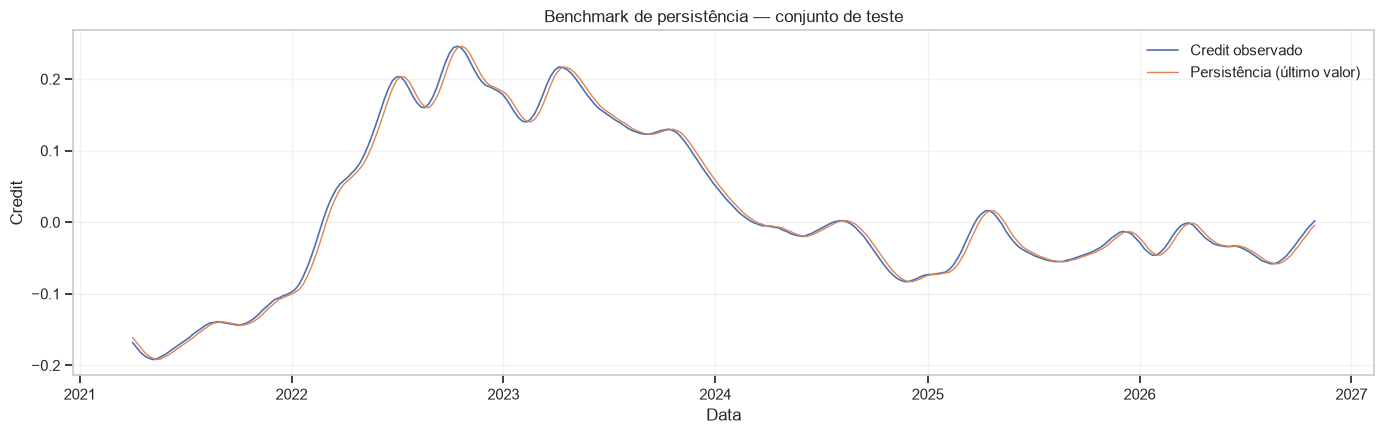

In [23]:
# Benchmark de persistência: prever Credit[t+1] usando o último valor conhecido Credit[t].
# A avaliação usa exatamente os mesmos índices-alvo das janelas supervisionadas.
def avaliar_persistencia(indices_alvo, serie_original, nome_particao):
    indices_alvo = np.asarray(indices_alvo, dtype=int)
    y_real = np.asarray(serie_original)[indices_alvo]
    y_previsto = np.asarray(serie_original)[indices_alvo - 1]
    metricas = calcular_metricas_regressao(y_real, y_previsto)
    return {"particao": nome_particao, "observacoes": len(indices_alvo), **metricas}

indices_por_particao = {
    "Treinamento": dados_univariados["idx_train"],
    "Validacao": dados_univariados["idx_val"],
    "Teste": dados_univariados["idx_test"],
}
resultados_persistencia = pd.DataFrame([
    avaliar_persistencia(indices, df[TARGET].to_numpy(), nome)
    for nome, indices in indices_por_particao.items()
])
display(resultados_persistencia)

idx_teste = indices_por_particao["Teste"]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(df.index[idx_teste], df[TARGET].to_numpy()[idx_teste], label="Credit observado", linewidth=1.2)
ax.plot(df.index[idx_teste], df[TARGET].to_numpy()[idx_teste - 1], label="Persistência (último valor)", linewidth=1.0)
ax.set_title("Benchmark de persistência — conjunto de teste")
ax.set_xlabel("Data")
ax.set_ylabel("Credit")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretação do benchmark.** A persistência alcança MAE aproximado de 0,0219 no treino, 0,0111 na validação e 0,0052 no teste; no teste, RMSE ≈ 0,0065 e R² ≈ 0,9966. É uma referência exigente para redes neurais. O teste apresenta erro particularmente baixo, coerente com menor volatilidade no período; não se deve interpretar esse número isoladamente como prova de generalização para todos os regimes. Os modelos devem ser comparados primeiro pela validação e depois avaliados no teste reservado.

## 8. Experimento univariado — oito arquiteturas

**Pergunta:** até que ponto cada arquitetura consegue prever `Credit[t+1]` usando exclusivamente o histórico de `Credit`? O experimento mantém as mesmas janelas, partições, target, scaler, loss, otimizador e quantidade máxima de épocas para tornar a comparação mais justa.

A previsão é de regressão, não classificação. Por isso, a função de custo será o erro quadrático médio (MSE) e a métrica acompanhada durante o treinamento será MAE. Não usaremos `accuracy` de classificação para um target contínuo. A acurácia direcional será calculada separadamente na escala original do índice.

### Arquiteturas exigidas

1. MLP de uma camada oculta.
2. MLP de duas camadas ocultas.
3. CNN 1D.
4. LSTM simples.
5. Stacked LSTM.
6. LSTM bidirecional.
7. CNN-LSTM.
8. ConvLSTM.

Os números de neurônios/filtros e kernels são hiperparâmetros experimentais iniciais, não valores prescritos por IFRS 9 ou pela Resolução CMN 4.966. O relatório deverá registrar essas escolhas.


### 8.1 Definição das arquiteturas e convenções comuns

Todos os modelos recebem janelas de 52 semanas e produzem uma única saída contínua. Os MLPs achatam a janela antes das camadas densas; CNNs aplicam convolução temporal causal; LSTMs processam a sequência na ordem observada. A versão bidirecional lê a janela histórica em ambas as direções, mas continua sem acessar dados posteriores ao instante previsto: todos os elementos da janela já são conhecidos em `t`.

Como referências conceituais, a LSTM foi introduzida por Hochreiter e Schmidhuber (1997), a aprendizagem convolucional é discutida por LeCun et al. (1998) e a arquitetura ConvLSTM foi proposta por Shi et al. (2015).

**Adaptação ConvLSTM:** uma série univariada não possui eixos espaciais naturais. Para exercitar a arquitetura ConvLSTM de maneira explícita, cada janela de 52 semanas será reorganizada em 13 blocos sucessivos de 4 semanas, tratados como uma pequena grade temporal. A ConvLSTM2D fará a recorrência entre blocos e a convolução dentro do bloco. Essa representação é uma adaptação didática, não uma interpretação espacial dos dados. A limitação será considerada na discussão.


In [24]:
# Construtores comuns aos 16 experimentos. Não há imports nesta célula.
EPOCHS_DIAGNOSTICO = 100
REUTILIZAR_DIAGNOSTICOS_EXISTENTES = True
FORCAR_REEXECUCAO_DIAGNOSTICOS = False
BATCH_SIZE = 32
LEARNING_RATE = 0.001

MODELOS_UNIVARIADOS = [
    "mlp_1", "mlp_2", "cnn", "lstm", "stacked_lstm",
    "bilstm", "cnn_lstm", "convlstm",
]
MODELOS_MULTIVARIADOS = [
    "mlp_1", "mlp_2", "mlp_multihead_1", "cnn", "cnn_multihead",
    "lstm", "stacked_lstm", "bilstm",
]

NOMES_MODELOS = {
    "mlp_1": "MLP — 1 camada oculta",
    "mlp_2": "MLP — 2 camadas ocultas",
    "mlp_multihead_1": "MLP multi-cabeça — 1 camada por variável",
    "cnn": "CNN 1D",
    "cnn_multihead": "CNN multi-cabeça",
    "lstm": "LSTM",
    "stacked_lstm": "Stacked LSTM",
    "bilstm": "LSTM bidirecional",
    "cnn_lstm": "CNN-LSTM",
    "convlstm": "ConvLSTM2D adaptada em blocos temporais",
}

def converter_entrada_modelo(modelo_id, X, modo, features):
    """Prepara o formato específico esperado por cada arquitetura."""
    X = np.asarray(X, dtype=np.float32)

    if modo == "univariado" and modelo_id == "convlstm":
        if WINDOW_SIZE % 4 != 0:
            raise ValueError(
                "Para ConvLSTM, WINDOW_SIZE deve ser múltiplo de 4."
            )

        # A entrada permanece em (amostras, 52 semanas, 1 feature).
        # A transformação para 5 dimensões será realizada dentro
        # da arquitetura, pela camada Reshape do modelo.
        return X

    if modo == "multivariado" and modelo_id in {
        "mlp_multihead_1",
        "cnn_multihead"
    }:
        # Um ramo independente por variável.
        return [
            X[:, :, i:i+1]
            for i in range(len(features))
        ]

    return X

def construir_modelo(modelo_id, modo, n_features):
    """Constrói uma arquitetura Keras univariada ou multivariada de saída única."""
    obter_tensorflow()
    camadas = tf.keras.layers
    entrada_shape = (WINDOW_SIZE, n_features)

    # Arquiteturas multivariadas multi-cabeça: cada feature possui seu próprio ramo.
    if modo == "multivariado" and modelo_id == "mlp_multihead_1":
        entradas, ramos = [], []
        for nome in FEATURES_MULTIVARIATE:
            inp = camadas.Input(shape=(WINDOW_SIZE, 1), name=f"entrada_{nome.lower()}")
            ramo = camadas.Flatten()(inp)
            ramo = camadas.Dense(16, activation="relu", name=f"dense_{nome.lower()}")(ramo)
            entradas.append(inp)
            ramos.append(ramo)
        combinado = camadas.Concatenate(name="concatenacao_dos_ramos")(ramos)
        saida = camadas.Dense(1, name="credit_t_mais_1")(combinado)
        modelo = tf.keras.Model(inputs=entradas, outputs=saida, name="mlp_multicabeca")

    elif modo == "multivariado" and modelo_id == "cnn_multihead":
        entradas, ramos = [], []
        for nome in FEATURES_MULTIVARIATE:
            inp = camadas.Input(shape=(WINDOW_SIZE, 1), name=f"entrada_{nome.lower()}")
            ramo = camadas.Conv1D(16, kernel_size=3, padding="causal", activation="relu")(inp)
            ramo = camadas.GlobalAveragePooling1D()(ramo)
            entradas.append(inp)
            ramos.append(ramo)
        combinado = camadas.Concatenate(name="concatenacao_dos_ramos")(ramos)
        combinado = camadas.Dense(32, activation="relu")(combinado)
        saida = camadas.Dense(1, name="credit_t_mais_1")(combinado)
        modelo = tf.keras.Model(inputs=entradas, outputs=saida, name="cnn_multicabeca")

    else:
        entrada = camadas.Input(shape=entrada_shape, name="historico_temporal")
        x = entrada

        if modelo_id == "mlp_1":
            x = camadas.Flatten()(x)
            x = camadas.Dense(64, activation="relu")(x)
        elif modelo_id == "mlp_2":
            x = camadas.Flatten()(x)
            x = camadas.Dense(64, activation="relu")(x)
            x = camadas.Dense(32, activation="relu")(x)
        elif modelo_id == "cnn":
            x = camadas.Conv1D(32, kernel_size=3, padding="causal", activation="relu")(x)
            x = camadas.GlobalAveragePooling1D()(x)
            x = camadas.Dense(32, activation="relu")(x)
        elif modelo_id == "lstm":
            x = camadas.LSTM(32)(x)
        elif modelo_id == "stacked_lstm":
            x = camadas.LSTM(32, return_sequences=True)(x)
            x = camadas.LSTM(16)(x)
        elif modelo_id == "bilstm":
            x = camadas.Bidirectional(camadas.LSTM(32))(x)
        elif modelo_id == "cnn_lstm":
            x = camadas.Conv1D(32, kernel_size=3, padding="causal", activation="relu")(x)
            x = camadas.LSTM(32)(x)
        elif modo == "univariado" and modelo_id == "convlstm":
            # ConvLSTM2D recebe (amostras, tempo, linhas, colunas, canais).
            x = camadas.Reshape((WINDOW_SIZE // 4, 4, 1, 1))(x)
            x = camadas.ConvLSTM2D(
                filters=16, kernel_size=(3, 1), padding="same", activation="tanh"
            )(x)
            x = camadas.Flatten()(x)
        else:
            raise ValueError(f"Arquitetura não reconhecida: modo={modo}, modelo={modelo_id}")

        saida = camadas.Dense(1, name="credit_t_mais_1")(x)
        modelo = tf.keras.Model(inputs=entrada, outputs=saida, name=f"{modo}_{modelo_id}")

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return modelo

print("Arquiteturas declaradas:")
display(pd.DataFrame([
    {"experimento": "Univariado", "id": m, "arquitetura": NOMES_MODELOS[m]}
    for m in MODELOS_UNIVARIADOS
] + [
    {"experimento": "Multivariado", "id": m, "arquitetura": NOMES_MODELOS[m]}
    for m in MODELOS_MULTIVARIADOS
]))


Arquiteturas declaradas:


,experimento,id,arquitetura
0,Univariado,mlp_1,MLP — 1 camada oculta
1,Univariado,mlp_2,MLP — 2 camadas ocultas
2,Univariado,cnn,CNN 1D
3,Univariado,lstm,LSTM
4,Univariado,stacked_lstm,Stacked LSTM
5,Univariado,bilstm,LSTM bidirecional
6,Univariado,cnn_lstm,CNN-LSTM
7,Univariado,convlstm,ConvLSTM2D adaptada em blocos temporais
8,Multivariado,mlp_1,MLP — 1 camada oculta
9,Multivariado,mlp_2,MLP — 2 camadas ocultas


### 8.2 Treinamento diagnóstico: curvas de custo e métrica

Cada arquitetura é treinada por até `EPOCHS_DIAGNOSTICO` épocas, acompanhando MSE (loss) e MAE em treinamento e validação. Não será usado *EarlyStopping*: a intenção é observar as curvas e localizar visualmente o início do overfitting ou o plateau, conforme o enunciado.

A tabela com o menor `val_loss` é uma referência numérica; a seleção também considera a forma das curvas. Os diagnósticos fornecidos foram limitados a 100 épocas. Quando o melhor ponto ocorre no limite, isso é assinalado como uma limitação em vez de ser declarado convergência.

In [25]:
def plotar_curvas_diagnostico(historico, titulo, caminho_saida=None):
    """Plota MSE e MAE de treino/validação e, opcionalmente, salva a figura."""
    h = historico.history if hasattr(historico, "history") else historico
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label="Treino")
    axes[0].plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label="Validação")
    axes[0].set_title("Função de custo — MSE")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("MSE (escala padronizada)")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(np.arange(1, len(h["mae"]) + 1), h["mae"], label="Treino")
    axes[1].plot(np.arange(1, len(h["val_mae"]) + 1), h["val_mae"], label="Validação")
    axes[1].set_title("Métrica — MAE")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("MAE (escala padronizada)")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    fig.tight_layout()
    if caminho_saida is not None:
        fig.savefig(caminho_saida, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def executar_diagnostico_modelos(modo, lista_modelos, dados, features):
    """Treina cada arquitetura com validação e guarda histórico e curvas."""
    obter_tensorflow()
    pasta = RESULTADOS_DIR / f"diagnostico_{modo}"
    pasta.mkdir(parents=True, exist_ok=True)
    configuracao = {
        "experimento": modo,
        "data_execucao": pd.Timestamp.now().isoformat(),
        "target": TARGET,
        "features": list(features),
        "lookback_semanas": WINDOW_SIZE,
        "horizonte_passos": 1,
        "epocas_diagnostico": EPOCHS_DIAGNOSTICO,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "loss": "mse",
        "metricas_treinamento": ["mae"],
        "random_state_base": RANDOM_STATE,
        "shuffle_janelas_treino": True,
    }
    (pasta / "configuracao.json").write_text(
        json.dumps(configuracao, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    X_train = dados["X_train"].astype(np.float32)
    y_train = dados["y_train"].astype(np.float32)
    X_val = dados["X_val"].astype(np.float32)
    y_val = dados["y_val"].astype(np.float32)
    historicos = {}
    linhas_resumo = []

    for posicao, modelo_id in enumerate(lista_modelos):
        print(f"[{posicao + 1}/{len(lista_modelos)}] Diagnóstico: {NOMES_MODELOS[modelo_id]}")
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(RANDOM_STATE + posicao)
        modelo = construir_modelo(modelo_id, modo, n_features=X_train.shape[2])
        entrada_train = converter_entrada_modelo(modelo_id, X_train, modo, features)
        entrada_val = converter_entrada_modelo(modelo_id, X_val, modo, features)
        historico = modelo.fit(
            entrada_train, y_train,
            validation_data=(entrada_val, y_val),
            epochs=EPOCHS_DIAGNOSTICO,
            batch_size=BATCH_SIZE,
            shuffle=True,  # apenas a ordem das janelas completas; a ordem interna não muda
            verbose=0,
            callbacks=[tf.keras.callbacks.TerminateOnNaN()],
        )
        h = historico.history
        historicos[modelo_id] = {k: [float(v) for v in valores] for k, valores in h.items()}
        pd.DataFrame(h).to_csv(pasta / f"{modelo_id}_historico.csv", index_label="epoca")
        plotar_curvas_diagnostico(
            historico,
            f"{modo.title()} — {NOMES_MODELOS[modelo_id]}",
            pasta / f"{modelo_id}_curvas.png",
        )
        melhor_epoca_val = int(np.argmin(h["val_loss"]) + 1)
        linhas_resumo.append({
            "modelo_id": modelo_id,
            "modelo": NOMES_MODELOS[modelo_id],
            "parametros": int(modelo.count_params()),
            "epoca_menor_val_mse_sugestao": melhor_epoca_val,
            "menor_val_mse_escalado": float(np.min(h["val_loss"])),
            "val_mae_na_melhor_epoca": float(h["val_mae"][melhor_epoca_val - 1]),
            "epocas_executadas": len(h["loss"]),
        })
        del modelo

    resumo = pd.DataFrame(linhas_resumo).sort_values("menor_val_mse_escalado")
    resumo.to_csv(pasta / "resumo_sugestoes_epoca.csv", index=False)
    (pasta / "historicos.json").write_text(json.dumps(historicos, ensure_ascii=False, indent=2), encoding="utf-8")
    return historicos, resumo

def carregar_diagnostico_existente(modo, lista_modelos, features):
    """Carrega históricos já salvos quando pertencem à configuração atual."""
    pasta = RESULTADOS_DIR / f"diagnostico_{modo}"
    caminho_config = pasta / "configuracao.json"
    caminho_resumo = pasta / "resumo_sugestoes_epoca.csv"

    if not caminho_config.exists() or not caminho_resumo.exists():
        return None

    try:
        config = json.loads(caminho_config.read_text(encoding="utf-8"))
        configuracao_compativel = (
            config.get("experimento") == modo
            and config.get("target") == TARGET
            and config.get("features") == list(features)
            and int(config.get("lookback_semanas", -1)) == WINDOW_SIZE
            and int(config.get("epocas_diagnostico", -1)) == EPOCHS_DIAGNOSTICO
            and int(config.get("batch_size", -1)) == BATCH_SIZE
            and float(config.get("learning_rate", -1)) == float(LEARNING_RATE)
        )
        if not configuracao_compativel:
            print(f"Diagnóstico salvo de {modo} não corresponde à configuração atual.")
            return None

        resumo = pd.read_csv(caminho_resumo)
        if set(resumo["modelo_id"].astype(str)) != set(lista_modelos):
            print(f"Diagnóstico salvo de {modo} não contém exatamente os modelos esperados.")
            return None

        historicos = {}
        colunas_obrigatorias = {"loss", "mae", "val_loss", "val_mae"}
        for modelo_id in lista_modelos:
            caminho_historico = pasta / f"{modelo_id}_historico.csv"
            if not caminho_historico.exists():
                return None
            serie = pd.read_csv(caminho_historico, index_col=0)
            if not colunas_obrigatorias.issubset(serie.columns) or serie.empty:
                return None
            historicos[modelo_id] = {
                coluna: serie[coluna].astype(float).tolist()
                for coluna in serie.columns
            }

        # Reexibe as curvas armazenadas no notebook, sem treinar novamente.
        for modelo_id in lista_modelos:
            plotar_curvas_diagnostico(
                historicos[modelo_id],
                f"{modo.title()} — {NOMES_MODELOS[modelo_id]} (diagnóstico salvo)",
                pasta / f"{modelo_id}_curvas.png",
            )

        print(
            f"Diagnóstico existente de {modo} carregado: "
            f"{len(lista_modelos)} históricos × {EPOCHS_DIAGNOSTICO} épocas. "
            "As curvas foram reexibidas; nenhum treinamento diagnóstico será repetido."
        )
        return historicos, resumo

    except Exception as exc:
        print(f"Não foi possível reutilizar o diagnóstico de {modo}: {exc}")
        return None


def obter_ou_executar_diagnostico(modo, lista_modelos, dados, features):
    """Reutiliza o diagnóstico compatível ou executa novamente se necessário."""
    if REUTILIZAR_DIAGNOSTICOS_EXISTENTES and not FORCAR_REEXECUCAO_DIAGNOSTICOS:
        carregado = carregar_diagnostico_existente(modo, lista_modelos, features)
        if carregado is not None:
            return carregado

    print(f"Executando diagnóstico neural de {modo}...")
    return executar_diagnostico_modelos(modo, lista_modelos, dados, features)


### 8.3 Carregar ou executar diagnóstico das oito arquiteturas univariadas

A célula seguinte procura os históricos e gráficos já salvos em `resultados_execucao/diagnostico_univariado/`. Se a configuração (target, features, lookback e hiperparâmetros) coincidir, as curvas são reexibidas sem novo treinamento. Se não houver histórico compatível, os oito diagnósticos são executados e os artefatos são gravados no diretório.

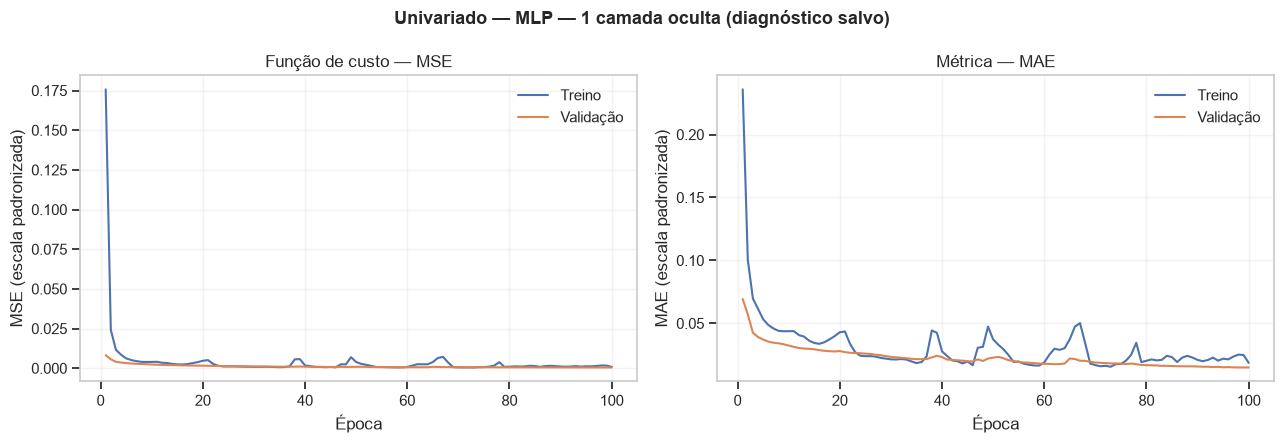

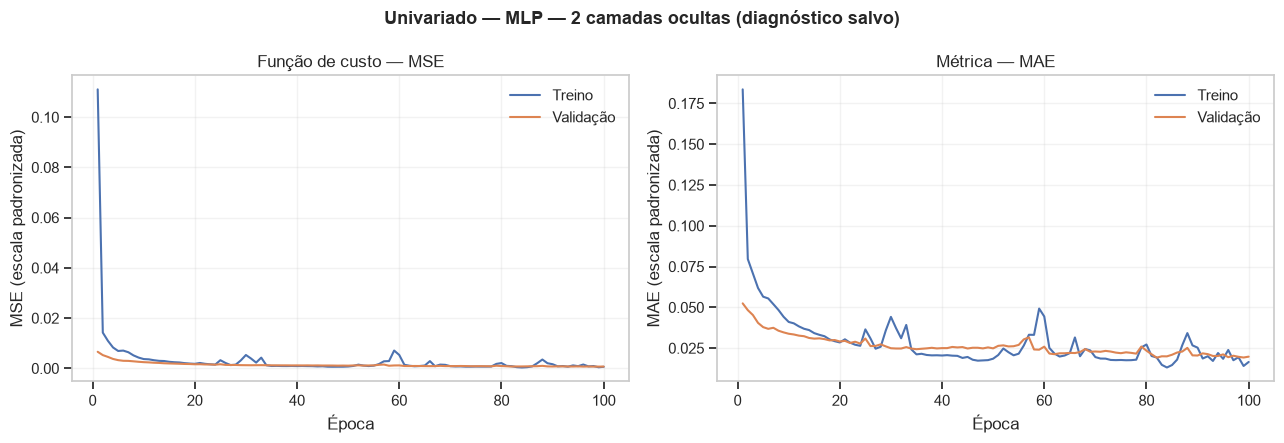

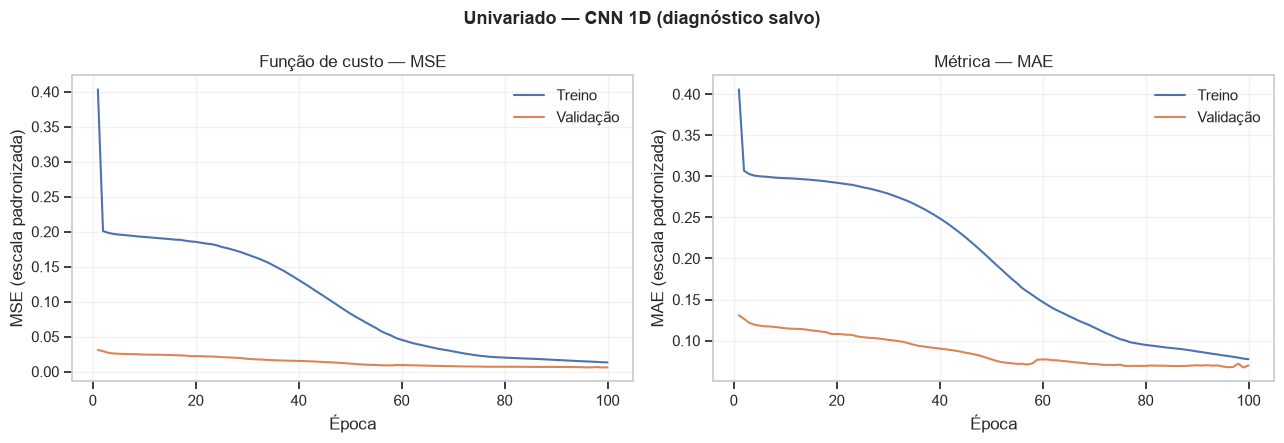

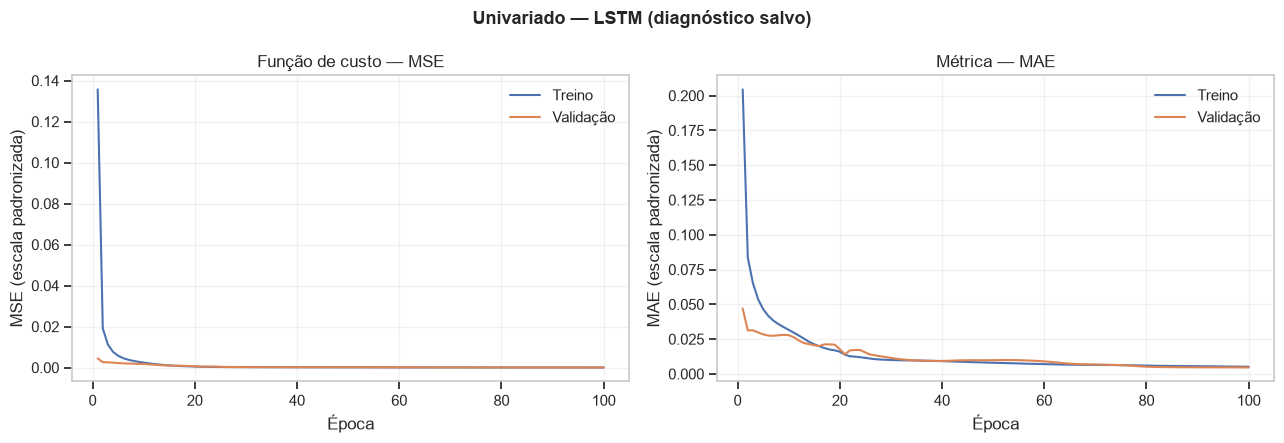

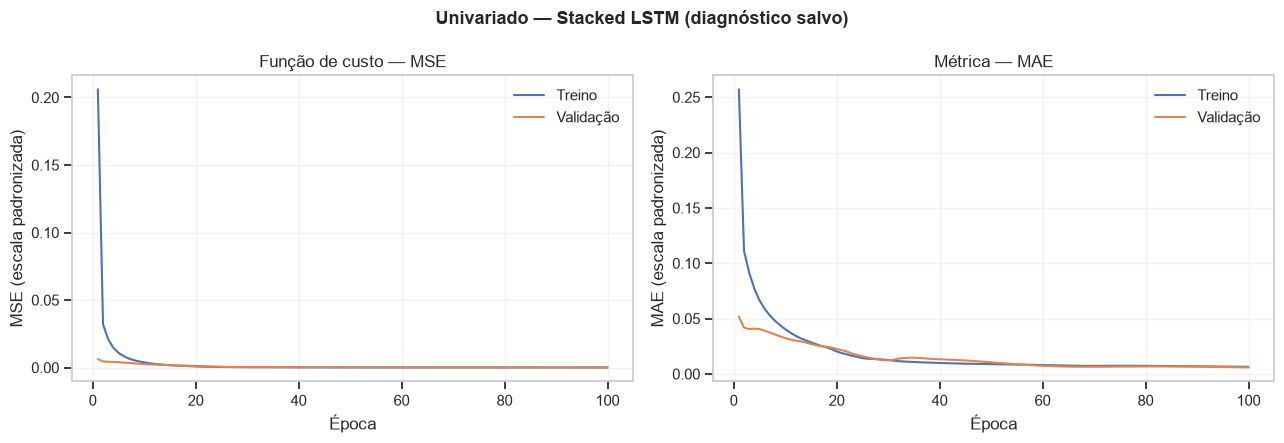

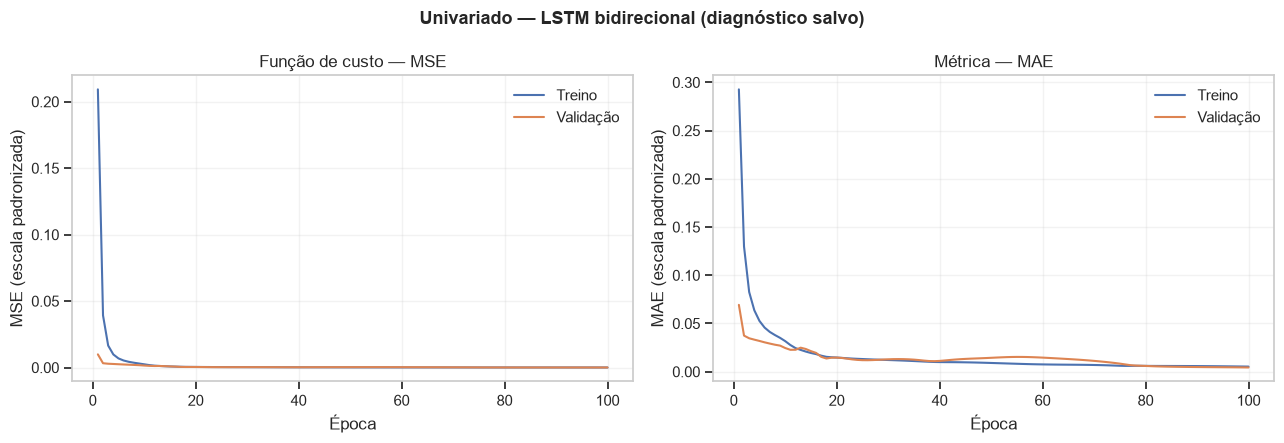

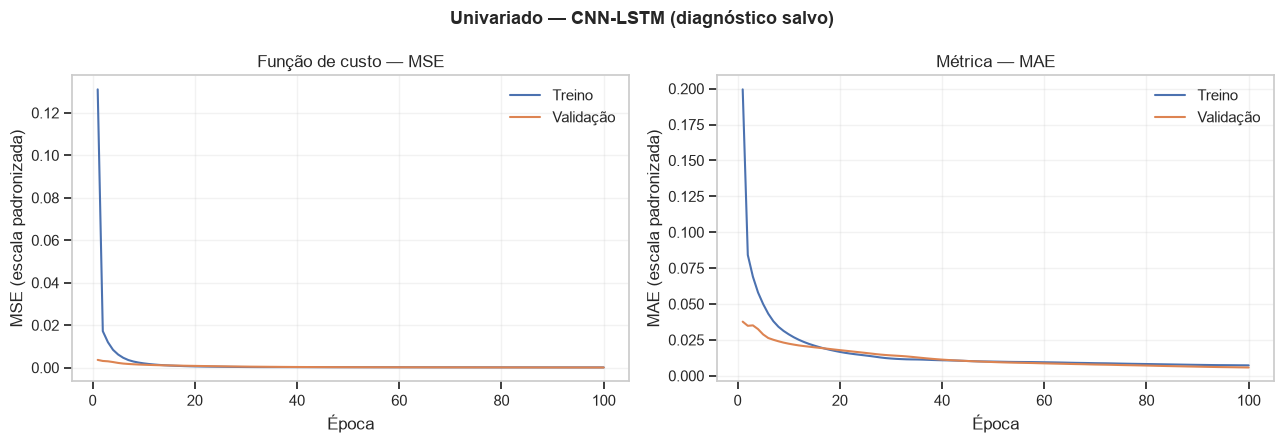

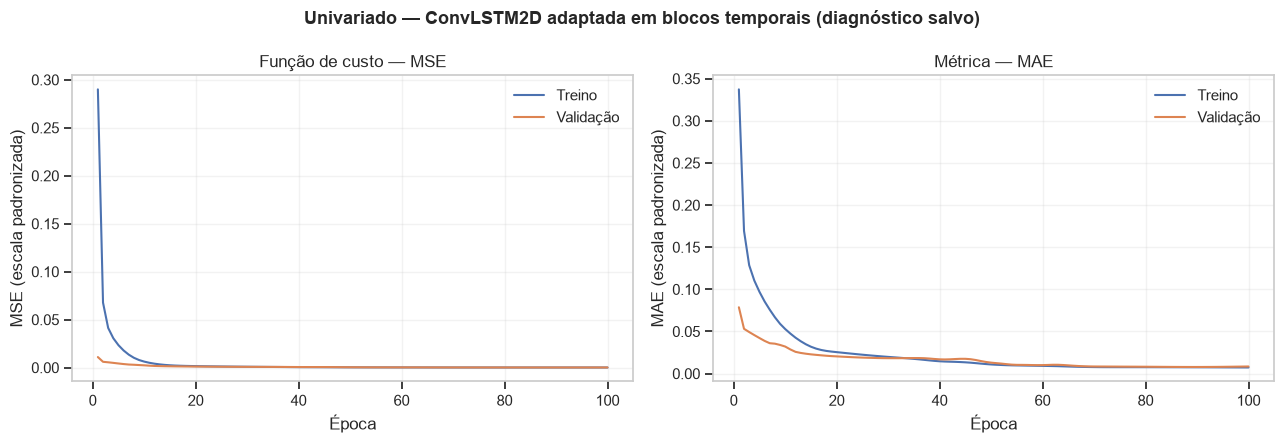

Diagnóstico existente de univariado carregado: 8 históricos × 100 épocas. As curvas foram reexibidas; nenhum treinamento diagnóstico será repetido.


,modelo_id,modelo,parametros,epoca_menor_val_mse_sugestao,menor_val_mse_escalado,val_mae_na_melhor_epoca,epocas_executadas
0,bilstm,LSTM bidirecional,8769,100,0.00004,0.00435,100
1,lstm,LSTM,4385,100,0.00005,0.00459,100
2,cnn_lstm,CNN-LSTM,8481,100,0.00007,0.00576,100
3,stacked_lstm,Stacked LSTM,7505,100,0.00007,0.00581,100
4,convlstm,ConvLSTM2D adaptada em blocos temporais,3393,92,0.00012,0.00789,100
5,mlp_1,MLP — 1 camada oculta,3457,100,0.00045,0.01493,100
6,mlp_2,MLP — 2 camadas ocultas,5505,99,0.00069,0.01924,100
7,cnn,CNN 1D,1217,99,0.00586,0.06732,100


In [26]:
if TENSORFLOW_DISPONIVEL:
    historicos_univariados, sugestoes_epoca_univariado = obter_ou_executar_diagnostico(
        modo="univariado",
        lista_modelos=MODELOS_UNIVARIADOS,
        dados=dados_univariados,
        features=FEATURES_UNIVARIATE,
    )
    display(sugestoes_epoca_univariado)
else:
    historicos_univariados, sugestoes_epoca_univariado = {}, pd.DataFrame()
    print("Diagnóstico não executado: instale as dependências de requirements.txt e execute novamente.")

### 8.4 Épocas selecionadas e retreinamento univariado

**O que significa retreinar?** Na fase de diagnóstico, cada modelo foi treinado para produzir curvas de erro de treinamento e validação. Essas curvas ajudam a escolher quantas épocas utilizar. O retreinamento cria uma nova instância da mesma arquitetura, com pesos reinicializados, e a treina do zero por exatamente o número de épocas selecionado. Depois, calcula as métricas nos conjuntos de treinamento, validação e teste.

A seleção das épocas já foi feita a partir dos históricos e gráficos fornecidos no ZIP. Ela está registrada em `resultados_execucao/selecao_epocas_retreinamento.csv`, com uma justificativa para cada arquitetura. **Você não precisa preencher dicionários nem alterar flags.** Basta executar o notebook de cima para baixo: os diagnósticos existentes serão reutilizados e o retreinamento será iniciado automaticamente.

A época foi escolhida pelo menor `val_loss` (MSE na escala padronizada), com inspeção da forma da curva. Em casos com mínimo nas últimas épocas do diagnóstico, a escolha representa o melhor ponto observado dentro do limite de 100 épocas; isso será tratado como limitação, não como prova de convergência.

In [27]:
# Seleção revisada a partir das curvas e históricos efetivamente enviados.
# As escolhas e suas justificativas ficam registradas em CSV para rastreabilidade.
CAMINHO_SELECAO_EPOCAS = RESULTADOS_DIR / "selecao_epocas_retreinamento.csv"

def carregar_selecao_epocas(modo, lista_modelos):
    tabela = pd.read_csv(CAMINHO_SELECAO_EPOCAS)
    selecao = tabela[tabela["experimento"] == modo].copy()

    faltantes = set(lista_modelos) - set(selecao["modelo_id"])
    excedentes = set(selecao["modelo_id"]) - set(lista_modelos)
    if faltantes or excedentes:
        raise ValueError(
            f"Seleção de épocas inconsistente para {modo}. "
            f"Faltantes: {sorted(faltantes)}; excedentes: {sorted(excedentes)}."
        )

    selecao = selecao.set_index("modelo_id").loc[lista_modelos].reset_index()
    epocas = {
        row["modelo_id"]: int(row["epocas_selecionadas"])
        for _, row in selecao.iterrows()
    }
    justificativas = {
        row["modelo_id"]: str(row["justificativa"])
        for _, row in selecao.iterrows()
    }
    if any(epoca < 1 for epoca in epocas.values()):
        raise ValueError("Todas as épocas selecionadas devem ser positivas.")

    display(selecao[[
        "modelo_id", "modelo", "epocas_selecionadas",
        "melhor_epoca_na_borda", "justificativa"
    ]])
    return epocas, justificativas

EPOCAS_SELECIONADAS_UNIVARIADO, JUSTIFICATIVAS_EPOCAS_UNIVARIADO = carregar_selecao_epocas(
    "univariado", MODELOS_UNIVARIADOS
)
print("Épocas univariadas e justificativas carregadas. O retreinamento começa na próxima célula.")

,modelo_id,modelo,epocas_selecionadas,melhor_epoca_na_borda,justificativa
0,mlp_1,MLP — 1 camada oculta,100,True,O menor MSE de validação ocorre na época 100. ...
1,mlp_2,MLP — 2 camadas ocultas,99,True,"O menor MSE de validação ocorre na época 99, s..."
2,cnn,CNN 1D,99,True,"O menor MSE de validação ocorre na época 99, c..."
3,lstm,LSTM,100,True,O MSE de validação continua diminuindo até a é...
4,stacked_lstm,Stacked LSTM,100,True,As curvas de treino e validação convergem e o ...
5,bilstm,LSTM bidirecional,100,True,A validação melhora até a época 100 e termina ...
6,cnn_lstm,CNN-LSTM,100,True,A curva de validação apresenta redução gradual...
7,convlstm,ConvLSTM2D adaptada em blocos temporais,92,False,O menor MSE de validação ocorre na época 92. A...


Épocas univariadas e justificativas carregadas. O retreinamento começa na próxima célula.


In [28]:
def calcular_metricas_regressao(y_true, y_pred, ultimo_observado=None):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    if len(y_true) != len(y_pred):
        raise ValueError("y_true e y_pred devem ter o mesmo tamanho.")
    metricas = {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mean_squared_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }
    if ultimo_observado is not None:
        ultimo_observado = np.asarray(ultimo_observado, dtype=float).reshape(-1)
        metricas["Acuracia_direcional"] = float(
            np.mean(np.sign(y_true - ultimo_observado) == np.sign(y_pred - ultimo_observado))
        )
    return metricas


def retreinar_e_avaliar_modelos(modo, lista_modelos, dados, features, epocas_selecionadas, justificativas):
    """Reinicializa, treina no bloco treino e avalia treino/validação/teste na escala original."""
    obter_tensorflow()
    faltantes = [m for m in lista_modelos if epocas_selecionadas.get(m) is None]
    justificativas_vazias = [m for m in lista_modelos if not str(justificativas.get(m, "")).strip()]
    invalidas = [m for m in lista_modelos if epocas_selecionadas.get(m) is not None and int(epocas_selecionadas[m]) < 1]
    if faltantes or justificativas_vazias or invalidas:
        raise ValueError(
            "Seleção de épocas incompleta. Confira resultados_execucao/selecao_epocas_retreinamento.csv. "
            f"Sem época: {faltantes}; sem justificativa: {justificativas_vazias}; épocas inválidas: {invalidas}."
        )

    particoes = {
        "Treinamento": ("X_train", "idx_train"),
        "Validacao": ("X_val", "idx_val"),
        "Teste": ("X_test", "idx_test"),
    }
    linhas_metricas, predicoes = [], []
    X_train = dados["X_train"].astype(np.float32)
    y_train = dados["y_train"].astype(np.float32)
    pasta = RESULTADOS_DIR / f"avaliacao_{modo}"
    pasta.mkdir(parents=True, exist_ok=True)
    configuracao_final = {
        "experimento": modo,
        "data_execucao": pd.Timestamp.now().isoformat(),
        "target": TARGET,
        "features": list(features),
        "lookback_semanas": WINDOW_SIZE,
        "horizonte_passos": 1,
        "epocas_selecionadas": {k: int(v) for k, v in epocas_selecionadas.items()},
        "justificativas_epoca": dict(justificativas),
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "loss": "mse",
        "random_state_base": RANDOM_STATE,
    }
    (pasta / "configuracao_retreinamento.json").write_text(
        json.dumps(configuracao_final, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    for posicao, modelo_id in enumerate(lista_modelos):
        epocas = int(epocas_selecionadas[modelo_id])
        print(f"Retreinando {NOMES_MODELOS[modelo_id]} por {epocas} épocas...")
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(RANDOM_STATE + posicao)
        modelo = construir_modelo(modelo_id, modo, n_features=X_train.shape[2])
        entrada_train = converter_entrada_modelo(modelo_id, X_train, modo, features)
        modelo.fit(
            entrada_train, y_train,
            epochs=epocas,
            batch_size=BATCH_SIZE,
            shuffle=True,
            verbose=0,
            callbacks=[tf.keras.callbacks.TerminateOnNaN()],
        )

        for nome_particao, (chave_X, chave_idx) in particoes.items():
            X_particao = dados[chave_X].astype(np.float32)
            idx = dados[chave_idx]
            entrada = converter_entrada_modelo(modelo_id, X_particao, modo, features)
            previsao_escalada = modelo.predict(entrada, verbose=0).reshape(-1, 1)
            previsao = dados["scaler_y"].inverse_transform(previsao_escalada).ravel()
            observado = dados["y_original"][idx]
            ultimo_observado = dados["y_original"][idx - 1]
            metricas = calcular_metricas_regressao(observado, previsao, ultimo_observado)
            linhas_metricas.append({
                "experimento": modo,
                "modelo_id": modelo_id,
                "modelo": NOMES_MODELOS[modelo_id],
                "epocas_escolhidas": epocas,
                "parametros": int(modelo.count_params()),
                "particao": nome_particao,
                **metricas,
                "justificativa_epoca": justificativas[modelo_id],
            })
            predicoes.append(pd.DataFrame({
                "experimento": modo,
                "modelo_id": modelo_id,
                "modelo": NOMES_MODELOS[modelo_id],
                "particao": nome_particao,
                "data": df.index[idx],
                "observado": observado,
                "previsto": previsao,
                "residuo": observado - previsao,
            }))
        del modelo

    tabela = pd.DataFrame(linhas_metricas)
    tabela_predicoes = pd.concat(predicoes, ignore_index=True)
    tabela.to_csv(pasta / f"metricas_{modo}.csv", index=False)
    tabela_predicoes.to_csv(pasta / f"predicoes_{modo}.csv", index=False)
    return tabela, tabela_predicoes


# Retreinamento final univariado: executado automaticamente, sem flags.
resultados_univariados = pd.DataFrame()
predicoes_univariadas = pd.DataFrame()
if TENSORFLOW_DISPONIVEL:
    resultados_univariados, predicoes_univariadas = retreinar_e_avaliar_modelos(
        "univariado", MODELOS_UNIVARIADOS, dados_univariados,
        FEATURES_UNIVARIATE, EPOCAS_SELECIONADAS_UNIVARIADO, JUSTIFICATIVAS_EPOCAS_UNIVARIADO
    )
    display(resultados_univariados)
else:
    print("Retreinamento univariado indisponível: instale as dependências de requirements.txt.")


Retreinando MLP — 1 camada oculta por 100 épocas...

Retreinando MLP — 2 camadas ocultas por 99 épocas...
Retreinando CNN 1D por 99 épocas...
Retreinando LSTM por 100 épocas...
Retreinando Stacked LSTM por 100 épocas...
Retreinando LSTM bidirecional por 100 épocas...
Retreinando CNN-LSTM por 100 épocas...
Retreinando ConvLSTM2D adaptada em blocos temporais por 92 épocas...


,experimento,modelo_id,modelo,epocas_escolhidas,parametros,particao,MAE,MSE,RMSE,R2,Acuracia_direcional,justificativa_epoca
0,univariado,mlp_1,MLP — 1 camada oculta,100,3457,Treinamento,0.01502,0.00044,0.02090,0.99969,0.70710,O menor MSE de validação ocorre na época 100. ...
1,univariado,mlp_1,MLP — 1 camada oculta,100,3457,Validacao,0.01776,0.00064,0.02530,0.98175,0.55842,O menor MSE de validação ocorre na época 100. ...
2,univariado,mlp_1,MLP — 1 camada oculta,100,3457,Teste,0.01377,0.00027,0.01656,0.97782,0.53082,O menor MSE de validação ocorre na época 100. ...
3,univariado,mlp_2,MLP — 2 camadas ocultas,99,5505,Treinamento,0.02290,0.00113,0.03355,0.99919,0.69502,"O menor MSE de validação ocorre na época 99, s..."
4,univariado,mlp_2,MLP — 2 camadas ocultas,99,5505,Validacao,0.02288,0.00098,0.03128,0.97211,0.51375,"O menor MSE de validação ocorre na época 99, s..."
5,univariado,mlp_2,MLP — 2 camadas ocultas,99,5505,Teste,0.01120,0.00020,0.01427,0.98351,0.55822,"O menor MSE de validação ocorre na época 99, s..."
6,univariado,cnn,CNN 1D,99,1217,Treinamento,0.09831,0.01824,0.13505,0.98687,0.52642,"O menor MSE de validação ocorre na época 99, c..."
7,univariado,cnn,CNN 1D,99,1217,Validacao,0.08005,0.00829,0.09103,0.76378,0.41581,"O menor MSE de validação ocorre na época 99, c..."
8,univariado,cnn,CNN 1D,99,1217,Teste,0.07710,0.00663,0.08143,0.46328,0.48973,"O menor MSE de validação ocorre na época 99, c..."
9,univariado,lstm,LSTM,100,4385,Treinamento,0.00463,0.00004,0.00659,0.99997,0.90237,O MSE de validação continua diminuindo até a é...


### 8.5 Comparação univariada e benchmark de persistência

A arquitetura será selecionada pela menor MAE de validação, com inspeção adicional de RMSE, R², acurácia direcional, diferença entre treino e validação e número de parâmetros. A persistência (`Credit[t+1] = Credit[t]`) é a referência mínima. O teste será exibido para avaliação final, mas não participará da escolha do vencedor.


,modelo,MAE,RMSE,R2,Acuracia_direcional,parametros
16,LSTM bidirecional,0.00517,0.00750,0.99840,0.82474,8769
10,LSTM,0.00546,0.00822,0.99807,0.81271,4385
19,CNN-LSTM,0.00685,0.00963,0.99736,0.78179,8481
13,Stacked LSTM,0.00691,0.00994,0.99718,0.80928,7505
22,ConvLSTM2D adaptada em blocos temporais,0.00938,0.01329,0.99497,0.69759,3393
25,Benchmark — persistência,0.01108,0.01794,0.99083,0.04467,0
1,MLP — 1 camada oculta,0.01776,0.02530,0.98175,0.55842,3457
4,MLP — 2 camadas ocultas,0.02288,0.03128,0.97211,0.51375,5505
7,CNN 1D,0.08005,0.09103,0.76378,0.41581,1217


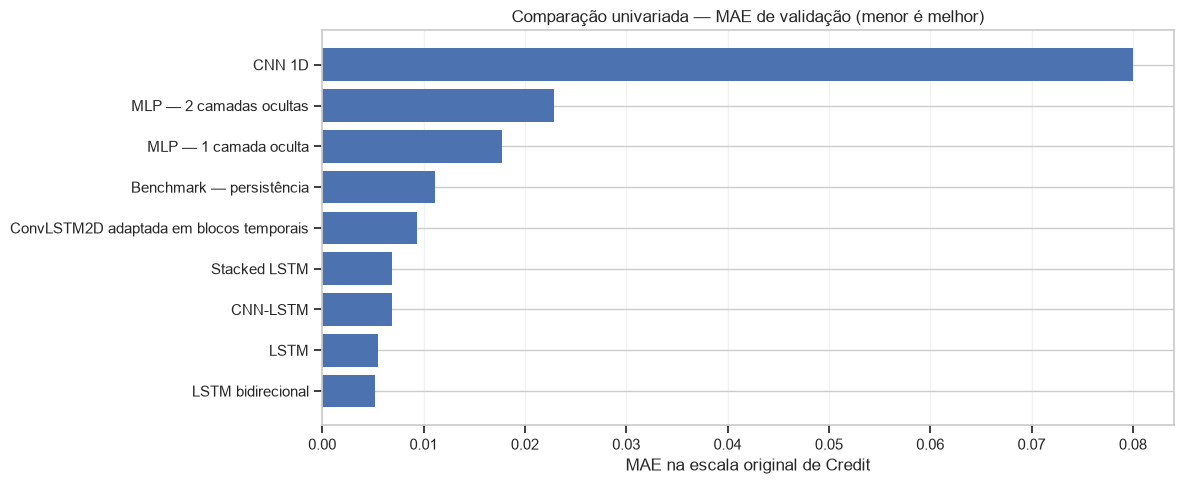

Melhor resultado univariado pela validação: LSTM bidirecional
A seleção não usa o conjunto de teste.


In [29]:
def tabela_benchmark_persistencia(dados, modo):
    linhas = []
    for particao, chave_idx in [
        ("Treinamento", "idx_train"), ("Validacao", "idx_val"), ("Teste", "idx_test")
    ]:
        idx = dados[chave_idx]
        real = dados["y_original"][idx]
        ultimo = dados["y_original"][idx - 1]
        linhas.append({
            "experimento": modo,
            "modelo_id": "persistencia",
            "modelo": "Benchmark — persistência",
            "epocas_escolhidas": 0,
            "parametros": 0,
            "particao": particao,
            **calcular_metricas_regressao(real, ultimo, ultimo),
            "justificativa_epoca": "Não se aplica: previsão igual ao último valor observado.",
        })
    return pd.DataFrame(linhas)


benchmark_univariado = tabela_benchmark_persistencia(dados_univariados, "univariado")
if not resultados_univariados.empty:
    comparacao_univariada = pd.concat([resultados_univariados, benchmark_univariado], ignore_index=True)
    validacao_univariada = comparacao_univariada[comparacao_univariada["particao"] == "Validacao"].sort_values("MAE")
    display(validacao_univariada[["modelo", "MAE", "RMSE", "R2", "Acuracia_direcional", "parametros"]])
    fig, ax = plt.subplots(figsize=(12, 5))
    plot_data = validacao_univariada.sort_values("MAE", ascending=True)
    ax.barh(plot_data["modelo"], plot_data["MAE"])
    ax.set_title("Comparação univariada — MAE de validação (menor é melhor)")
    ax.set_xlabel("MAE na escala original de Credit")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(RESULTADOS_DIR / "comparacao_univariada_validacao.png", dpi=150, bbox_inches="tight")
    plt.show()
    melhor_univariado_id = validacao_univariada.iloc[0]["modelo_id"]
    print("Melhor resultado univariado pela validação:", validacao_univariada.iloc[0]["modelo"])
    print("A seleção não usa o conjunto de teste.")
else:
    comparacao_univariada = pd.DataFrame()
    melhor_univariado_id = None
    print("Comparação final univariada será exibida após a execução do retreinamento univariado.")


## 9. Experimento multivariado de saída única — oito arquiteturas

**Pergunta:** os subíndices `Risk`, `Leverage` e `Nonfinancial_Leverage`, combinados com o histórico de `Credit`, adicionam informação útil para prever `Credit[t+1]`?

A saída continua sendo exclusivamente o próximo valor de `Credit`. As variáveis adicionais são entradas observadas até a semana `t`; não será utilizada informação futura. Os mesmos cortes cronológicos, lookback de 52 semanas, scaler ajustado somente no treino, loss, otimizador e batch size usados no experimento univariado serão mantidos.

As arquiteturas são: MLP 1 camada, MLP 2 camadas, MLP multi-cabeça, CNN 1D, CNN multi-cabeça, LSTM, Stacked LSTM e LSTM bidirecional.

**Desenho multi-cabeça:** cada variável possui um ramo próprio, que transforma sua sequência histórica em uma representação. As representações são concatenadas antes da camada final de regressão. Essa arquitetura permite aprender representações específicas por indicador antes de combiná-las. Ela não prova causalidade nem importância econômica independente.


### 9.1 Carregar ou executar diagnóstico multivariado

O protocolo é idêntico ao univariado: até 100 épocas, sem parada automática, monitorando MSE e MAE em treino/validação. Os históricos salvos são reutilizados quando a configuração coincide; caso contrário, os oito diagnósticos são executados. A comparação permite verificar se as variáveis adicionais ajudam ou apenas aumentam a complexidade.

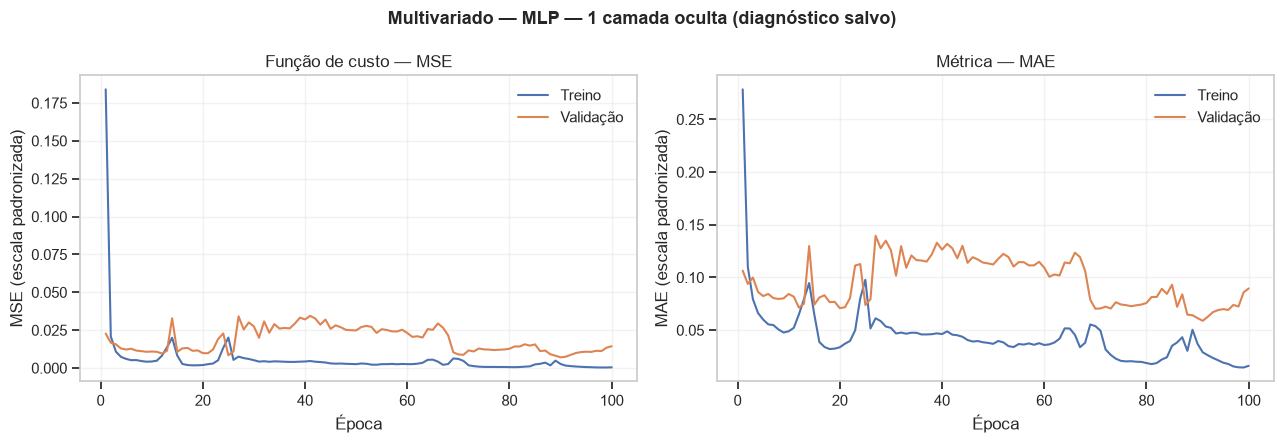

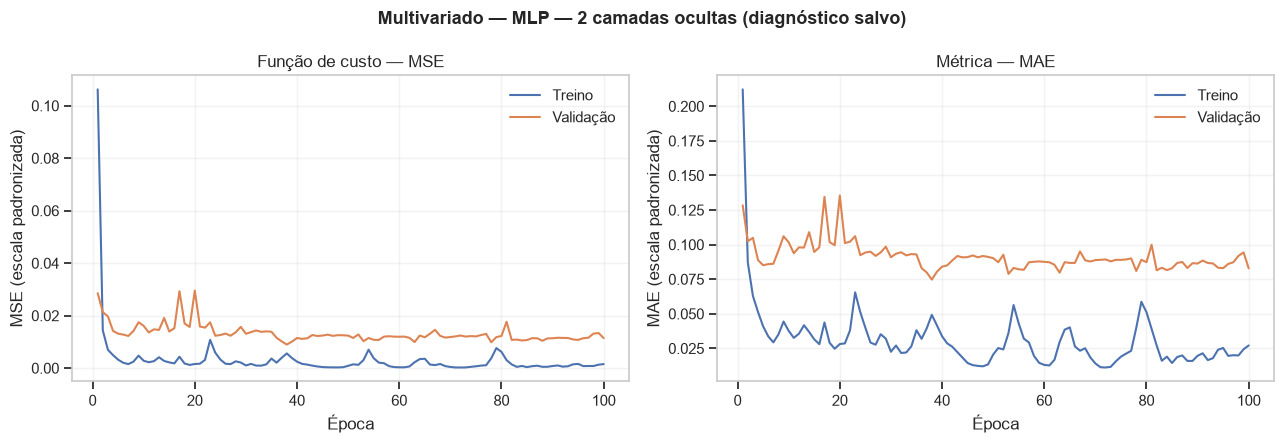

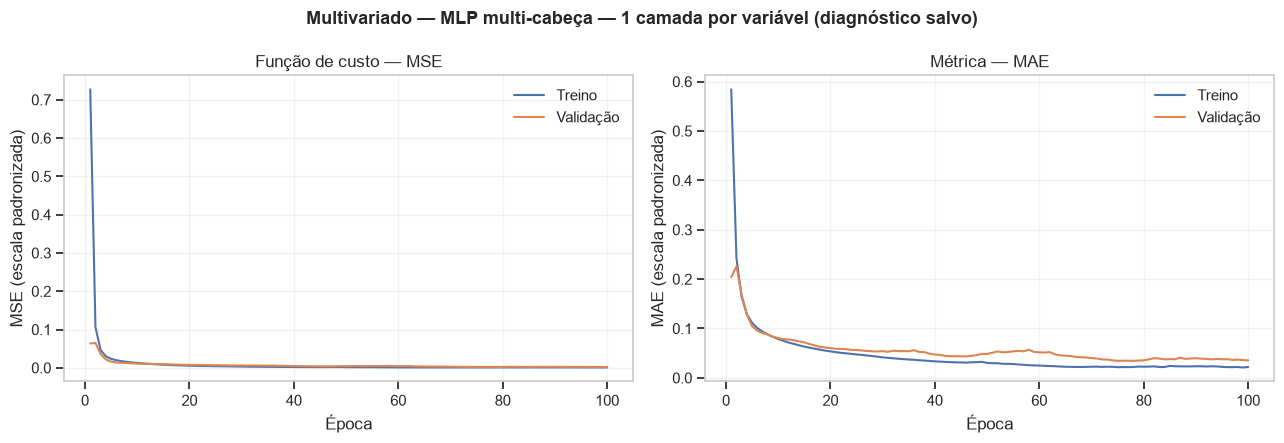

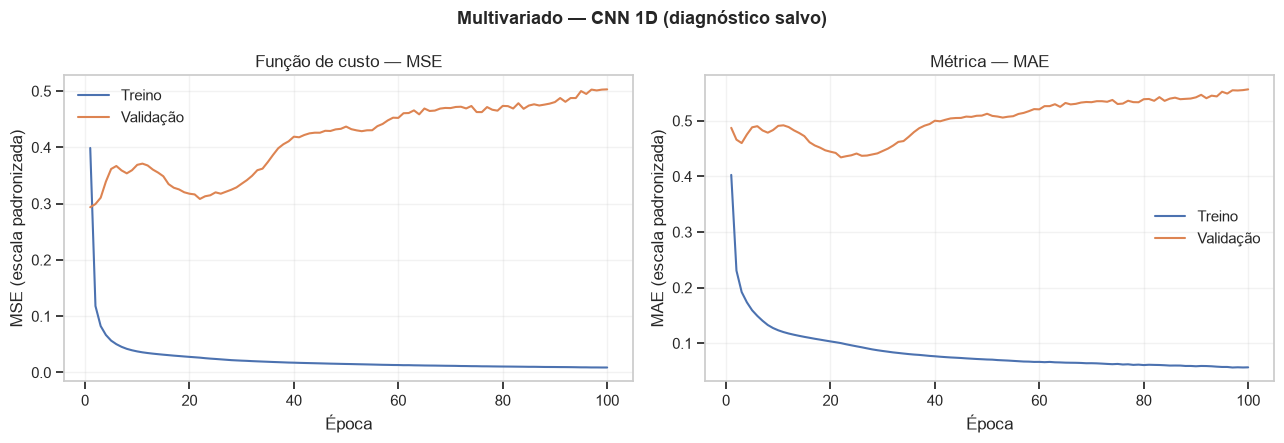

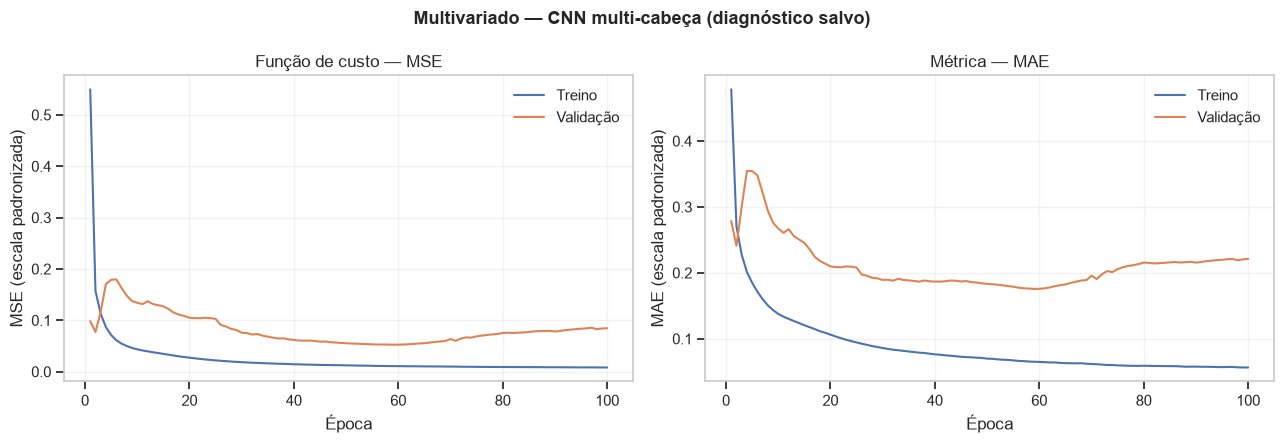

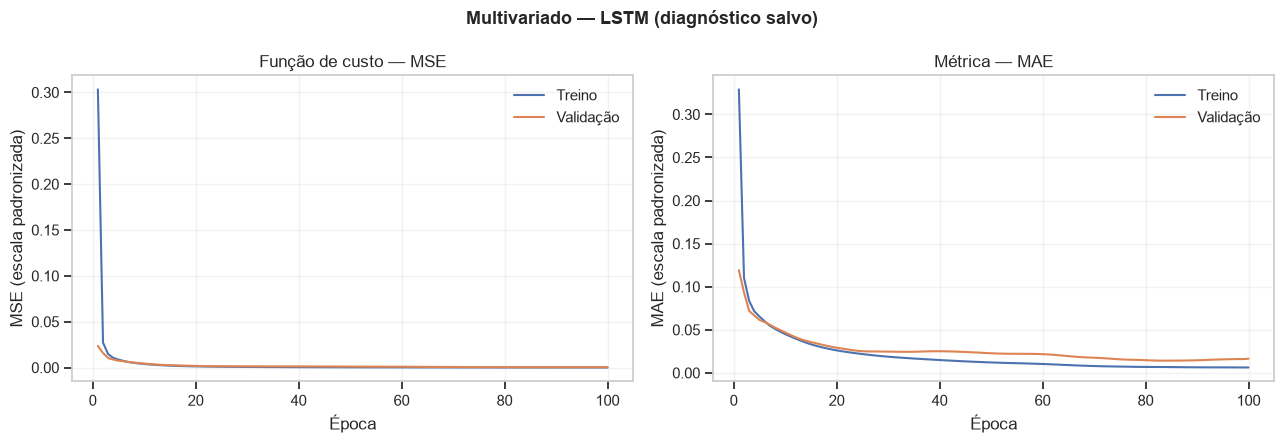

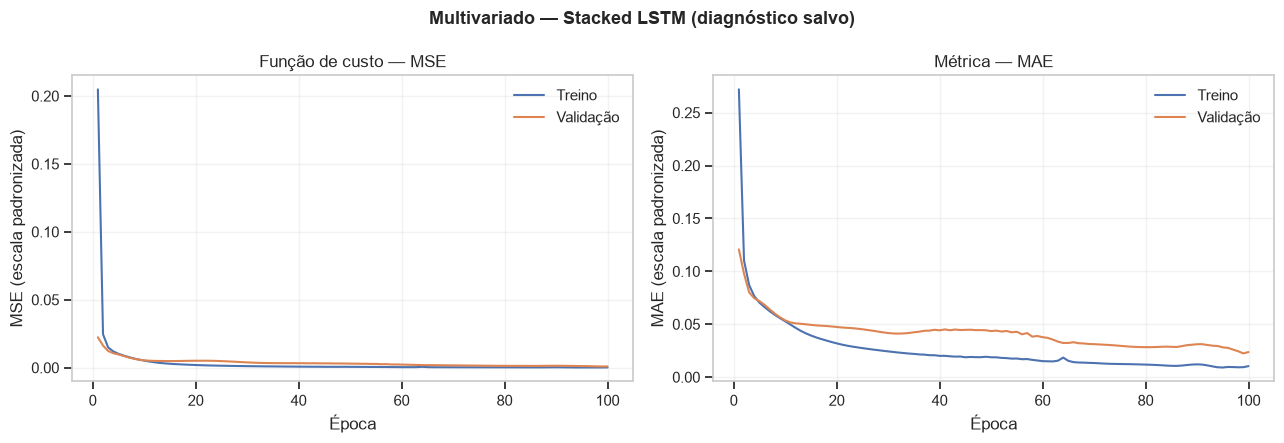

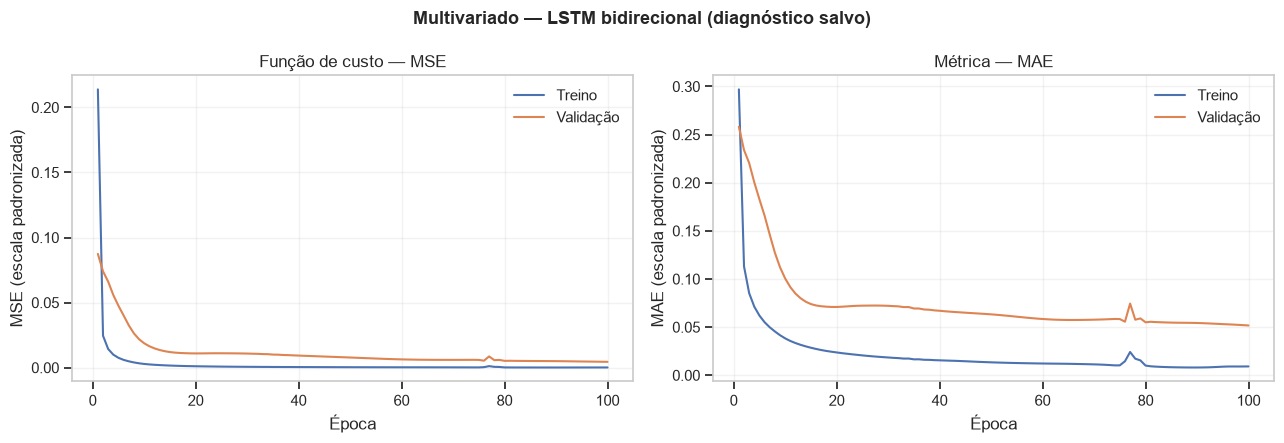

Diagnóstico existente de multivariado carregado: 8 históricos × 100 épocas. As curvas foram reexibidas; nenhum treinamento diagnóstico será repetido.


,modelo_id,modelo,parametros,epoca_menor_val_mse_sugestao,menor_val_mse_escalado,val_mae_na_melhor_epoca,epocas_executadas
0,lstm,LSTM,4769,88,0.00036,0.01432,100
1,stacked_lstm,Stacked LSTM,7889,99,0.00091,0.02242,100
2,mlp_multihead_1,MLP multi-cabeça — 1 camada por variável,3457,100,0.00206,0.03531,100
3,bilstm,LSTM bidirecional,9537,100,0.00446,0.05171,100
4,mlp_1,MLP — 1 camada oculta,13441,90,0.00706,0.06139,100
5,mlp_2,MLP — 2 camadas ocultas,15489,38,0.00897,0.07471,100
6,cnn_multihead,CNN multi-cabeça,2369,59,0.05246,0.17558,100
7,cnn,CNN 1D,1505,1,0.29368,0.48737,100


In [30]:
if TENSORFLOW_DISPONIVEL:
    historicos_multivariados, sugestoes_epoca_multivariado = obter_ou_executar_diagnostico(
        modo="multivariado",
        lista_modelos=MODELOS_MULTIVARIADOS,
        dados=dados_multivariados,
        features=FEATURES_MULTIVARIATE,
    )
    display(sugestoes_epoca_multivariado)
else:
    historicos_multivariados, sugestoes_epoca_multivariado = {}, pd.DataFrame()
    print("Diagnóstico multivariado não executado: instale TensorFlow e execute novamente.")

### 9.2 Épocas selecionadas e retreinamento multivariado

O mesmo procedimento é aplicado ao experimento multivariado. As épocas foram escolhidas pela inspeção das curvas de validação disponibilizadas, e as justificativas estão registradas no CSV de seleção.

**Não é necessário preencher nada manualmente.** A célula seguinte carrega as escolhas e o retreinamento inicia automaticamente quando o notebook é executado de cima para baixo. Cada arquitetura é recriada com pesos novos, treinada somente no conjunto de treinamento pelo número de épocas selecionado e avaliada em treino, validação e teste.

A abordagem multivariada não deve ser considerada superior apenas por utilizar mais variáveis. O benchmark de persistência e o experimento univariado são referências obrigatórias.

In [31]:
EPOCAS_SELECIONADAS_MULTIVARIADO, JUSTIFICATIVAS_EPOCAS_MULTIVARIADO = carregar_selecao_epocas(
    "multivariado", MODELOS_MULTIVARIADOS
)
print("Épocas multivariadas e justificativas carregadas. O retreinamento começa na próxima célula.")

,modelo_id,modelo,epocas_selecionadas,melhor_epoca_na_borda,justificativa
0,mlp_1,MLP — 1 camada oculta,90,False,A validação atinge o menor MSE na época 90 e p...
1,mlp_2,MLP — 2 camadas ocultas,38,False,O menor MSE de validação ocorre na época 38. D...
2,mlp_multihead_1,MLP multi-cabeça — 1 camada por variável,100,True,O MSE de validação continua diminuindo até a é...
3,cnn,CNN 1D,1,False,O menor MSE de validação ocorre já na época 1;...
4,cnn_multihead,CNN multi-cabeça,59,False,O MSE de validação diminui até a época 59 e de...
5,lstm,LSTM,88,False,A validação atinge o menor MSE na época 88 e p...
6,stacked_lstm,Stacked LSTM,99,True,A validação continua melhorando até a época 99...
7,bilstm,LSTM bidirecional,100,True,O MSE de validação continua diminuindo até a é...


Épocas multivariadas e justificativas carregadas. O retreinamento começa na próxima célula.


In [32]:
# Retreinamento final multivariado: executado automaticamente, sem flags.
resultados_multivariados = pd.DataFrame()
predicoes_multivariadas = pd.DataFrame()
if TENSORFLOW_DISPONIVEL:
    resultados_multivariados, predicoes_multivariadas = retreinar_e_avaliar_modelos(
        "multivariado", MODELOS_MULTIVARIADOS, dados_multivariados,
        FEATURES_MULTIVARIATE, EPOCAS_SELECIONADAS_MULTIVARIADO, JUSTIFICATIVAS_EPOCAS_MULTIVARIADO
    )
    display(resultados_multivariados)
else:
    print("Retreinamento multivariado indisponível: instale as dependências de requirements.txt.")


Retreinando MLP — 1 camada oculta por 90 épocas...
Retreinando MLP — 2 camadas ocultas por 38 épocas...
Retreinando MLP multi-cabeça — 1 camada por variável por 100 épocas...
Retreinando CNN 1D por 1 épocas...
Retreinando CNN multi-cabeça por 59 épocas...
Retreinando LSTM por 88 épocas...
Retreinando Stacked LSTM por 99 épocas...
Retreinando LSTM bidirecional por 100 épocas...


,experimento,modelo_id,modelo,epocas_escolhidas,parametros,particao,MAE,MSE,RMSE,R2,Acuracia_direcional,justificativa_epoca
0,multivariado,mlp_1,MLP — 1 camada oculta,90,13441,Treinamento,0.04807,0.00479,0.06920,0.99655,0.62104,A validação atinge o menor MSE na época 90 e p...
1,multivariado,mlp_1,MLP — 1 camada oculta,90,13441,Validacao,0.07300,0.00999,0.09993,0.71536,0.48454,A validação atinge o menor MSE na época 90 e p...
2,multivariado,mlp_1,MLP — 1 camada oculta,90,13441,Teste,0.06061,0.00552,0.07431,0.55306,0.42466,A validação atinge o menor MSE na época 90 e p...
3,multivariado,mlp_2,MLP — 2 camadas ocultas,38,15489,Treinamento,0.04878,0.00429,0.06553,0.99691,0.59285,O menor MSE de validação ocorre na época 38. D...
4,multivariado,mlp_2,MLP — 2 camadas ocultas,38,15489,Validacao,0.08884,0.01268,0.11261,0.63849,0.49485,O menor MSE de validação ocorre na época 38. D...
5,multivariado,mlp_2,MLP — 2 camadas ocultas,38,15489,Teste,0.07984,0.00978,0.09891,0.20810,0.56164,O menor MSE de validação ocorre na época 38. D...
6,multivariado,mlp_multihead_1,MLP multi-cabeça — 1 camada por variável,100,3457,Treinamento,0.02182,0.00087,0.02948,0.99937,0.70357,O MSE de validação continua diminuindo até a é...
7,multivariado,mlp_multihead_1,MLP multi-cabeça — 1 camada por variável,100,3457,Validacao,0.04199,0.00291,0.05397,0.91697,0.51890,O MSE de validação continua diminuindo até a é...
8,multivariado,mlp_multihead_1,MLP multi-cabeça — 1 camada por variável,100,3457,Teste,0.04672,0.00333,0.05770,0.73053,0.53767,O MSE de validação continua diminuindo até a é...
9,multivariado,cnn,CNN 1D,1,1505,Treinamento,0.31579,0.20989,0.45813,0.84885,0.45596,O menor MSE de validação ocorre já na época 1;...


### 9.3 Comparação multivariada e benchmark de persistência

A tabela será ordenada pela MAE da validação. Compare especialmente o modelo multivariado vencedor com o benchmark de persistência e com o melhor resultado univariado. Um ganho pequeno de erro pode não justificar mais parâmetros ou maior instabilidade. Nenhuma arquitetura será escolhida pelo menor erro no teste.


,modelo,MAE,RMSE,R2,Acuracia_direcional,parametros
25,Benchmark — persistência,0.01108,0.01794,0.99083,0.04467,0
16,LSTM,0.01703,0.02246,0.98562,0.57216,4769
19,Stacked LSTM,0.02667,0.03597,0.96311,0.36942,7889
7,MLP multi-cabeça — 1 camada por variável,0.04199,0.05397,0.91697,0.51890,3457
22,LSTM bidirecional,0.06149,0.07940,0.82028,0.46220,9537
1,MLP — 1 camada oculta,0.07300,0.09993,0.71536,0.48454,13441
4,MLP — 2 camadas ocultas,0.08884,0.11261,0.63849,0.49485,15489
13,CNN multi-cabeça,0.20880,0.27239,-1.11502,0.57732,2369
10,CNN 1D,0.57958,0.64445,-10.83936,0.53952,1505


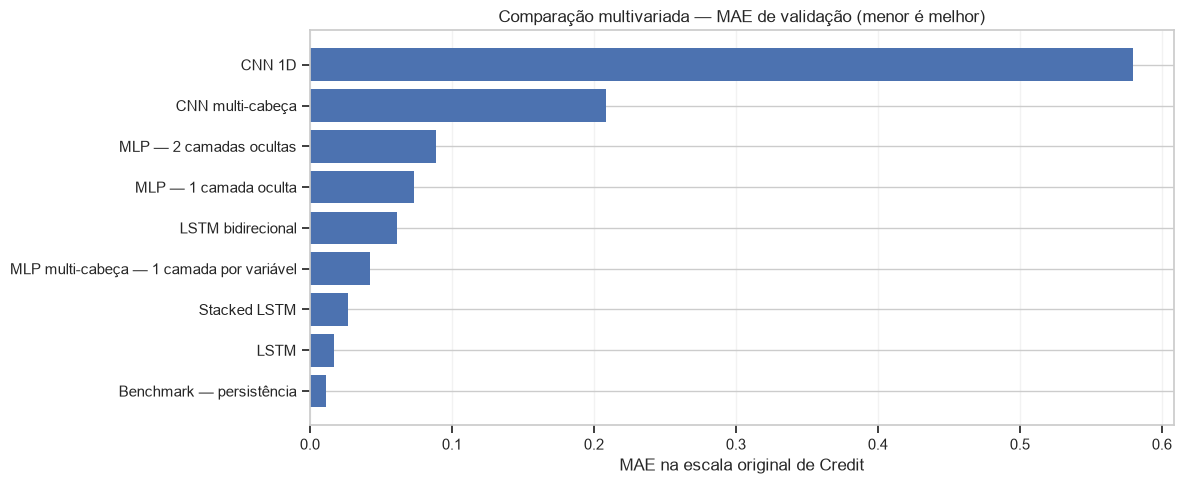

Melhor resultado multivariado pela validação: Benchmark — persistência


In [33]:
benchmark_multivariado = tabela_benchmark_persistencia(dados_multivariados, "multivariado")
if not resultados_multivariados.empty:
    comparacao_multivariada = pd.concat([resultados_multivariados, benchmark_multivariado], ignore_index=True)
    validacao_multivariada = comparacao_multivariada[comparacao_multivariada["particao"] == "Validacao"].sort_values("MAE")
    display(validacao_multivariada[["modelo", "MAE", "RMSE", "R2", "Acuracia_direcional", "parametros"]])
    fig, ax = plt.subplots(figsize=(12, 5))
    plot_data = validacao_multivariada.sort_values("MAE", ascending=True)
    ax.barh(plot_data["modelo"], plot_data["MAE"])
    ax.set_title("Comparação multivariada — MAE de validação (menor é melhor)")
    ax.set_xlabel("MAE na escala original de Credit")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(RESULTADOS_DIR / "comparacao_multivariada_validacao.png", dpi=150, bbox_inches="tight")
    plt.show()
    melhor_multivariado_id = validacao_multivariada.iloc[0]["modelo_id"]
    print("Melhor resultado multivariado pela validação:", validacao_multivariada.iloc[0]["modelo"])
else:
    comparacao_multivariada = pd.DataFrame()
    melhor_multivariado_id = None
    print("Comparação final multivariada será exibida após a execução do retreinamento multivariado.")


## 10. Comparação geral, interpretação e conclusão

A decisão final precisa responder três perguntas: (1) qual arquitetura apresenta melhor desempenho na validação? (2) a abordagem multivariada melhora a previsão em relação à univariada? (3) os modelos neurais superam o benchmark de persistência o suficiente para justificar sua complexidade?

A seleção é baseada em validação. O teste é apresentado depois como estimativa final de desempenho fora da amostra, sem voltar atrás para alterar janela, arquitetura ou épocas. Se o teste contrariar a validação, essa diferença deve ser discutida como evidência de mudança de regime/instabilidade e não como convite para otimizar sobre o teste.


In [34]:
# Quadro comparativo consolidado, caso as duas etapas de retreinamento tenham sido confirmadas.
if not resultados_univariados.empty and not resultados_multivariados.empty:
    todos_resultados = pd.concat([resultados_univariados, resultados_multivariados], ignore_index=True)
    benchmark_geral = pd.concat([benchmark_univariado, benchmark_multivariado], ignore_index=True)
    quadro_geral = pd.concat([todos_resultados, benchmark_geral], ignore_index=True)
    vencedores_validacao = (
        quadro_geral[quadro_geral["particao"] == "Validacao"]
        .sort_values("MAE")
        .reset_index(drop=True)
    )
    display(vencedores_validacao[["experimento", "modelo", "MAE", "RMSE", "R2", "Acuracia_direcional", "parametros"]])

    # Comparação univariado x multivariado: melhor modelo de cada abordagem pela validação.
    melhor_uni = resultados_univariados[resultados_univariados["particao"] == "Validacao"].sort_values("MAE").iloc[0]
    melhor_multi = resultados_multivariados[resultados_multivariados["particao"] == "Validacao"].sort_values("MAE").iloc[0]
    resumo_vencedores = pd.DataFrame([melhor_uni, melhor_multi])
    display(resumo_vencedores[["experimento", "modelo", "epocas_escolhidas", "MAE", "RMSE", "R2", "Acuracia_direcional", "parametros"]])

    melhor_modelo_geral = vencedores_validacao.iloc[0]
    print("Melhor modelo segundo a validação:", melhor_modelo_geral["experimento"], "—", melhor_modelo_geral["modelo"])
    print("A avaliação de teste deste modelo será reportada sem reotimização.")

    # Teste: reportar métricas de todos os modelos já selecionados/retreinados, sem ranqueá-los para nova seleção.
    resultados_teste = quadro_geral[quadro_geral["particao"] == "Teste"].copy()
    display(resultados_teste[["experimento", "modelo", "MAE", "RMSE", "R2", "Acuracia_direcional"]])
    quadro_geral.to_csv(RESULTADOS_DIR / "comparacao_geral_metricas.csv", index=False)
else:
    todos_resultados = pd.DataFrame()
    quadro_geral = pd.DataFrame()
    print("Comparação geral pendente: execute os diagnósticos, registre as épocas manualmente e confirme os dois retreinamentos.")


,experimento,modelo,MAE,RMSE,R2,Acuracia_direcional,parametros
0,univariado,LSTM bidirecional,0.00517,0.00750,0.99840,0.82474,8769
1,univariado,LSTM,0.00546,0.00822,0.99807,0.81271,4385
2,univariado,CNN-LSTM,0.00685,0.00963,0.99736,0.78179,8481
3,univariado,Stacked LSTM,0.00691,0.00994,0.99718,0.80928,7505
4,univariado,ConvLSTM2D adaptada em blocos temporais,0.00938,0.01329,0.99497,0.69759,3393
5,univariado,Benchmark — persistência,0.01108,0.01794,0.99083,0.04467,0
6,multivariado,Benchmark — persistência,0.01108,0.01794,0.99083,0.04467,0
7,multivariado,LSTM,0.01703,0.02246,0.98562,0.57216,4769
8,univariado,MLP — 1 camada oculta,0.01776,0.02530,0.98175,0.55842,3457
9,univariado,MLP — 2 camadas ocultas,0.02288,0.03128,0.97211,0.51375,5505


,experimento,modelo,epocas_escolhidas,MAE,RMSE,R2,Acuracia_direcional,parametros
16,univariado,LSTM bidirecional,100,0.00517,0.00750,0.99840,0.82474,8769
16,multivariado,LSTM,88,0.01703,0.02246,0.98562,0.57216,4769


Melhor modelo segundo a validação: univariado — LSTM bidirecional
A avaliação de teste deste modelo será reportada sem reotimização.


,experimento,modelo,MAE,RMSE,R2,Acuracia_direcional
2,univariado,MLP — 1 camada oculta,0.01377,0.01656,0.97782,0.53082
5,univariado,MLP — 2 camadas ocultas,0.01120,0.01427,0.98351,0.55822
8,univariado,CNN 1D,0.07710,0.08143,0.46328,0.48973
11,univariado,LSTM,0.00301,0.00369,0.99890,0.84589
14,univariado,Stacked LSTM,0.00441,0.00534,0.99769,0.77740
17,univariado,LSTM bidirecional,0.00237,0.00312,0.99921,0.87671
20,univariado,CNN-LSTM,0.00385,0.00478,0.99815,0.80822
23,univariado,ConvLSTM2D adaptada em blocos temporais,0.00649,0.00764,0.99527,0.67123
26,multivariado,MLP — 1 camada oculta,0.06061,0.07431,0.55306,0.42466
29,multivariado,MLP — 2 camadas ocultas,0.07984,0.09891,0.20810,0.56164


### 10.1 Leitura dos erros no tempo

As métricas agregadas podem esconder diferenças entre regimes financeiros. O gráfico a seguir compara observado e previsto no período de teste para o melhor modelo selecionado pela validação em cada abordagem. O objetivo é verificar se o modelo acompanha movimentos de estresse, se suaviza excessivamente picos e se apresenta erros persistentes.


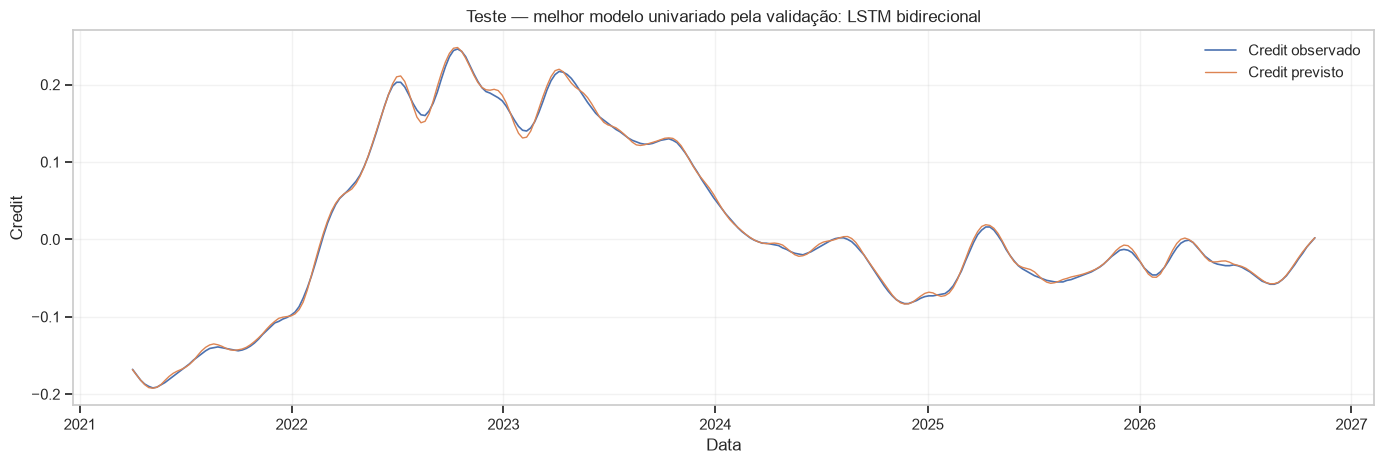

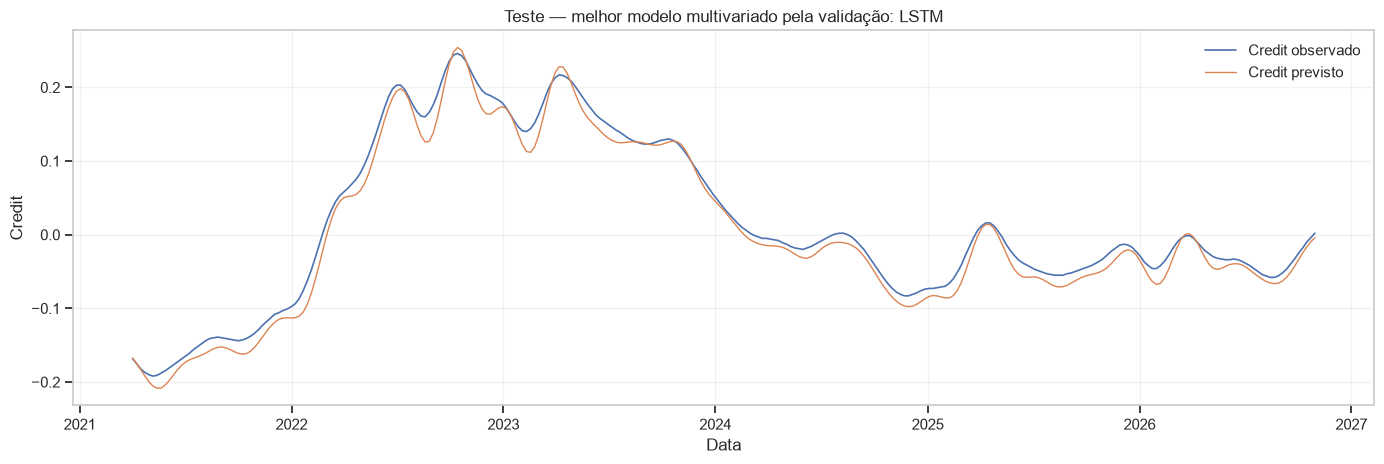

In [35]:
def plotar_previsoes_teste(predicoes, modelo_id, titulo, caminho):
    if predicoes.empty:
        print("Previsões ainda não disponíveis.")
        return
    selecionado = predicoes[
        (predicoes["modelo_id"] == modelo_id) & (predicoes["particao"] == "Teste")
    ].sort_values("data")
    if selecionado.empty:
        print(f"Não há previsões de teste para {modelo_id}.")
        return
    fig, ax = plt.subplots(figsize=(14, 4.8))
    ax.plot(selecionado["data"], selecionado["observado"], label="Credit observado", linewidth=1.2)
    ax.plot(selecionado["data"], selecionado["previsto"], label="Credit previsto", linewidth=1.0)
    ax.set_title(titulo)
    ax.set_xlabel("Data")
    ax.set_ylabel("Credit")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(caminho, dpi=150, bbox_inches="tight")
    plt.show()

if not resultados_univariados.empty:
    melhor_id_uni = resultados_univariados.query("particao == 'Validacao'").sort_values("MAE").iloc[0]["modelo_id"]
    plotar_previsoes_teste(
        predicoes_univariadas, melhor_id_uni,
        f"Teste — melhor modelo univariado pela validação: {NOMES_MODELOS[melhor_id_uni]}",
        RESULTADOS_DIR / "melhor_univariado_teste.png",
    )
if not resultados_multivariados.empty:
    melhor_id_multi = resultados_multivariados.query("particao == 'Validacao'").sort_values("MAE").iloc[0]["modelo_id"]
    plotar_previsoes_teste(
        predicoes_multivariadas, melhor_id_multi,
        f"Teste — melhor modelo multivariado pela validação: {NOMES_MODELOS[melhor_id_multi]}",
        RESULTADOS_DIR / "melhor_multivariado_teste.png",
    )


### 10.2 Limitações e interpretação financeira

- `Credit` é um subíndice agregado de condições de crédito dos Estados Unidos; não é LGD, PD, EAD, default, taxa de inadimplência ou provisão.
- A relação com IFRS 9 e Resolução CMN 4.966 é de contextualização: variáveis macrofinanceiras prospectivas podem integrar análises de risco e cenários, mas este experimento não estima perdas esperadas contábeis nem valida modelo regulatório.
- Os indicadores `Risk`, `Leverage` e `Nonfinancial_Leverage` são componentes relacionados ao mesmo sistema de condições financeiras; multicolinearidade e conteúdo informacional sobreposto podem limitar o ganho das features adicionais.
- O conjunto é semanal, agregado e referente aos Estados Unidos. Não há dados individuais de operações, contratos, recuperações, garantias ou clientes.
- A janela de 52 semanas é baseline experimental e não foi comprovada como ótima nem como sazonalidade anual.
- ConvLSTM usa uma organização em blocos temporais artificiais, pois a série não possui dimensão espacial natural.
- As épocas atualmente selecionadas foram revistas a partir das curvas recebidas e estão justificadas em CSV; modelos com melhor ponto nas épocas 99/100 atingiram o limite do diagnóstico e não têm convergência comprovada.
- O resultado do teste é específico do período final observado e não garante desempenho sob futuros regimes econômicos.


## 10.3 Discussão comparativa dos resultados

A comparação utiliza a **MAE de validação como critério primário de seleção**, mantendo o conjunto de teste reservado à avaliação fora da amostra. RMSE e R² complementam a leitura: o RMSE penaliza mais os erros de maior magnitude, enquanto o R² expressa a proporção de variabilidade explicada em cada partição. A acurácia direcional é apresentada somente como indicador complementar, pois não substitui uma métrica de erro para regressão.

### 10.3.1 Resultado univariado

| Modelo | Épocas | MAE validação | RMSE validação | R² validação | MAE teste | RMSE teste | R² teste |
|---|---:|---:|---:|---:|---:|---:|---:|
| MLP — 1 camada oculta | 100 | 0.017759 | 0.025301 | 0.981752 | 0.013771 | 0.016555 | 0.977816 |
| MLP — 2 camadas ocultas | 99 | 0.022881 | 0.031278 | 0.972112 | 0.011201 | 0.014273 | 0.983512 |
| CNN 1D | 99 | 0.080053 | 0.091030 | 0.763782 | 0.077095 | 0.081431 | 0.463282 |
| LSTM | 100 | 0.005459 | 0.008219 | 0.998074 | 0.003010 | 0.003695 | 0.998895 |
| Stacked LSTM | 100 | 0.006911 | 0.009939 | 0.997184 | 0.004411 | 0.005344 | 0.997688 |
| LSTM bidirecional (BiLSTM) | 100 | 0.005171 | 0.007501 | 0.998396 | 0.002368 | 0.003123 | 0.999211 |
| CNN-LSTM | 100 | 0.006850 | 0.009627 | 0.997358 | 0.003849 | 0.004784 | 0.998147 |
| ConvLSTM2D adaptada | 92 | 0.009384 | 0.013286 | 0.994968 | 0.006492 | 0.007642 | 0.995273 |
| Persistência | — | 0.011082 | 0.017940 | 0.990825 | 0.005188 | 0.006529 | 0.996549 |

A **BiLSTM** foi selecionada como melhor arquitetura univariada pela validação, com MAE de **0,005171** e RMSE de **0,007501**. A LSTM convencional ficou próxima (MAE 0,005459), seguida por CNN-LSTM e Stacked LSTM. No teste, a BiLSTM manteve a primeira posição entre os modelos avaliados, com MAE de **0,002368**, RMSE de **0,003123** e R² de **0,999211**.

Em relação ao benchmark de persistência, a BiLSTM reduziu a MAE em **53,34% na validação** (0,011082 para 0,005171) e **54,36% no teste** (0,005188 para 0,002368). A redução de RMSE foi de aproximadamente 58,19% na validação e 52,17% no teste. Portanto, neste recorte temporal, a BiLSTM não apenas ajustou a série: ela superou uma referência simples que já explora a elevada persistência de `Credit`.

A LSTM simples também superou a persistência nas duas partições, embora com erro um pouco maior que a BiLSTM. CNN-LSTM e Stacked LSTM apresentaram resultados competitivos. A ConvLSTM adaptada ficou abaixo dessas arquiteturas recorrentes e híbridas, mas ainda superou a persistência na validação; no teste, sua MAE foi ligeiramente maior que a do benchmark. As duas MLPs tiveram desempenho inferior à persistência na validação e no teste. A CNN 1D apresentou o maior erro entre os modelos univariados, sugerindo que a arquitetura convolucional utilizada, com essa configuração e esse conjunto de dados, não representou tão bem a dinâmica temporal quanto as redes recorrentes.

### 10.3.2 Resultado multivariado

| Modelo | Épocas | MAE validação | RMSE validação | R² validação | MAE teste | RMSE teste | R² teste |
|---|---:|---:|---:|---:|---:|---:|---:|
| MLP — 1 camada oculta | 90 | 0.073005 | 0.099926 | 0.715357 | 0.060608 | 0.074310 | 0.553057 |
| MLP — 2 camadas ocultas | 38 | 0.088845 | 0.112613 | 0.638489 | 0.079837 | 0.098913 | 0.208098 |
| MLP multi-cabeça | 100 | 0.041994 | 0.053968 | 0.916972 | 0.046724 | 0.057699 | 0.730535 |
| CNN 1D | 1 | 0.579581 | 0.644453 | -10.839359 | 0.608189 | 0.642907 | -32.454797 |
| CNN multi-cabeça | 59 | 0.208799 | 0.272386 | -1.115017 | 0.141071 | 0.178483 | -1.578422 |
| LSTM | 88 | 0.017032 | 0.022459 | 0.985621 | 0.012216 | 0.014274 | 0.983510 |
| Stacked LSTM | 99 | 0.026665 | 0.035972 | 0.963113 | 0.022087 | 0.026000 | 0.945283 |
| LSTM bidirecional (BiLSTM) | 100 | 0.061488 | 0.079402 | 0.820277 | 0.079576 | 0.092230 | 0.311497 |
| Persistência | — | 0.011082 | 0.017940 | 0.990825 | 0.005188 | 0.006529 | 0.996549 |

A **LSTM** foi a melhor arquitetura multivariada pela validação, com MAE de **0,017032** e RMSE de **0,022459**. Entretanto, esse resultado foi **53,68% pior em MAE** do que a persistência na validação. No teste, a MAE da LSTM foi **0,012216**, enquanto a persistência obteve **0,005188**: o erro da LSTM foi aproximadamente **135,44% maior**. Nenhuma das oito arquiteturas multivariadas superou a persistência em MAE na validação ou no teste.

A inclusão de `Risk`, `Leverage` e `Nonfinancial_Leverage`, portanto, **não trouxe ganho preditivo incremental neste desenho experimental**. Isso não demonstra que essas variáveis sejam irrelevantes em qualquer horizonte ou especificação. Significa apenas que, com as features, o lookback fixo, as arquiteturas, os hiperparâmetros e as partições utilizados, o histórico univariado de `Credit` forneceu informação mais útil para a previsão de um passo à frente. Correlação contemporânea entre subíndices não garante informação antecipatória adicional; além disso, os componentes pertencem ao mesmo sistema de indicadores e podem compartilhar conteúdo informacional.

### 10.3.3 Comparação entre as abordagens e leitura temporal

Na validação, a MAE do melhor modelo multivariado (LSTM, 0,017032) foi **229,39% maior** que a MAE do melhor modelo univariado (BiLSTM, 0,005171). A diferença também se manteve no teste. O resultado favorece a abordagem univariada para a tarefa específica investigada e não sustenta a hipótese de que acrescentar os três subíndices melhora automaticamente a previsão de `Credit`.

Os erros absolutos do teste foram menores que os da validação para o benchmark e para a maioria dos modelos. Isso deve ser interpretado à luz da distribuição observada: o desvio-padrão de `Credit` foi aproximadamente **0,1875 na validação** e **0,1113 no teste**. O período de teste apresentou menor dispersão, de modo que comparar diretamente MAEs entre partições sem considerar a variabilidade seria inadequado. A comparação mais informativa é modelo contra benchmark **dentro da mesma partição**.

A acurácia direcional da BiLSTM foi de **82,47% na validação** e **87,67% no teste**. A persistência apresentou 4,47% e 4,11%, respectivamente. Esse valor baixo da persistência tem uma explicação matemática: como sua previsão é exatamente o último valor observado, ela prevê variação zero; o indicador só considera acerto quando o valor seguinte realmente permanece inalterado. Por isso, a acurácia direcional deve ser lida com cautela e não usada isoladamente para declarar superioridade.

### 10.3.4 Seleção de épocas, janela e reprodutibilidade

As épocas foram selecionadas a partir da menor perda de validação observada, com inspeção das curvas. Alguns diagnósticos atingiram o limite de 100 épocas sem evidência de reversão clara; nesses casos, a época registrada é o melhor ponto **dentro do intervalo testado**, não uma prova de convergência. Outros apresentaram sinais de overfitting antes do limite, como a CNN multivariada (melhor ponto na primeira época), a MLP de duas camadas multivariada (38 épocas) e a CNN multi-cabeça (59 épocas). Essas diferenças reforçam que a duração adequada do treinamento depende da arquitetura.

O *lookback* de **52 semanas foi mantido como escolha operacional fixa** para padronizar a comparação das arquiteturas e oferecer aproximadamente um ano de contexto semanal. Não foi realizado um experimento de desempenho com 13, 26 e 104 semanas; portanto, 52 não deve ser chamado de ótimo, nem associado a sazonalidade anual comprovada. A lista alternativa apresentada anteriormente serve apenas para ilustrar o custo amostral de diferentes janelas.

Cada arquitetura foi executada uma única vez com seed base 42 e seed derivada da posição do modelo. Não foram realizadas repetições com múltiplas seeds nem validação temporal de origem móvel. Assim, os resultados são reproduzíveis quanto à configuração documentada, mas a variabilidade entre inicializações e diferentes origens temporais não foi quantificada. O notebook registra o Python 3.14.4 no metadado do kernel; a versão exata de TensorFlow/Keras e o dispositivo utilizado não foram capturados nos outputs originais. O hash SHA-256 do CSV e a impressão digital das fontes do notebook estão em `resultados_execucao/proveniencia_execucao.json`; a captura completa de ambiente ficará disponível nas próximas execuções pelo script `tools/capture_execution_provenance.py`.


## 10.4 Conclusão

Este trabalho comparou oito arquiteturas de redes neurais no cenário univariado e oito no cenário multivariado para prever, com horizonte de uma semana, o subíndice `Credit` do National Financial Conditions Index (NFCI). A análise foi realizada sobre 2.913 observações semanais entre 8 de janeiro de 1971 e 30 de outubro de 2026, com separação cronológica em treinamento, validação e teste, lookback operacional de 52 semanas e avaliação frente a um benchmark de persistência.

Os resultados indicam que a **abordagem univariada apresentou o melhor desempenho**. A LSTM bidirecional foi selecionada pela menor MAE de validação (0,005171) e confirmou o resultado no período de teste (MAE 0,002368). Em ambas as partições, superou o benchmark de persistência, reduzindo a MAE em 53,34% na validação e 54,36% no teste. A LSTM convencional também apresentou desempenho competitivo, enquanto CNN-LSTM e Stacked LSTM tiveram resultados próximos. Entre as arquiteturas avaliadas, a CNN 1D apresentou desempenho inferior.

No cenário multivariado, a LSTM foi a melhor das oito arquiteturas pela validação, mas não superou o benchmark de persistência. Nenhum dos modelos multivariados obteve MAE menor que a referência simples na validação ou no teste. Portanto, para esta base, este horizonte e esta configuração experimental, a inclusão de `Risk`, `Leverage` e `Nonfinancial_Leverage` não melhorou a previsão em relação ao uso exclusivo do histórico de `Credit`.

A evidência responde à questão experimental: **é possível prever o próximo valor de `Credit` com redes neurais, mas o ganho depende da arquitetura e da especificação das entradas**. Neste estudo, a BiLSTM univariada foi a alternativa mais eficaz. A comparação também mostra que maior quantidade de variáveis e maior complexidade arquitetural não garantem melhor generalização; um benchmark simples deve permanecer como referência obrigatória.

A relevância financeira do estudo é contextual. O subíndice `Credit` resume condições agregadas do mercado de crédito dos Estados Unidos e pode ajudar a discutir a dinâmica macrofinanceira que acompanha avaliações de risco e cenários econômicos. Entretanto, ele **não representa PD, LGD, EAD, default, inadimplência ou perda esperada de uma carteira**. Assim, o modelo desenvolvido não calcula provisão contábil, não estima diretamente perdas esperadas da IFRS 9 ou da Resolução CMN nº 4.966 e não deve ser interpretado como modelo regulatório. Sua contribuição é demonstrar, em ambiente acadêmico, como arquiteturas de redes neurais podem ser comparadas na previsão de um indicador macrofinanceiro relacionado às condições de crédito.

Os resultados devem ser considerados à luz de limitações: o lookback de 52 semanas foi fixado e não otimizado; cada arquitetura teve uma única execução; não foi realizada validação de origem móvel; parte das curvas atingiu o limite de 100 épocas; a ConvLSTM foi adaptada por blocos temporais artificiais, sem estrutura espacial natural; e a base é agregada e referente aos Estados Unidos. Estudos futuros poderiam avaliar múltiplas seeds, diferentes origens temporais, janelas alternativas e variáveis macroeconômicas externas, sempre selecionando configurações pela validação e mantendo um teste final intocado.

Conclui-se que a BiLSTM univariada foi a melhor arquitetura **entre as alternativas e condições testadas**, mas essa conclusão não implica superioridade universal da arquitetura nem aplicação direta ao cálculo de provisões bancárias. O experimento evidencia a importância de comparar redes neurais com baselines simples, separar seleção e avaliação final e interpretar os resultados dentro dos limites informacionais da série utilizada.


## 11. Referências

BANCO CENTRAL DO BRASIL. **Resolução CMN nº 4.966, de 25 de novembro de 2021.** Dispõe sobre os conceitos e os critérios contábeis aplicáveis a instrumentos financeiros e a constituição de provisão para perdas esperadas associadas ao risco de crédito. Versão consolidada indicada pelo Banco Central como atualizada em 29 ago. 2025. Disponível em: <https://www.bcb.gov.br/estabilidadefinanceira/exibenormativo?numero=4966&tipo=RESOLU%C3%87%C3%83O+CMN>. Acesso em: 9 nov. 2026.

BANCO CENTRAL DO BRASIL. **Resolução CMN nº 5.244, de 28 de agosto de 2025.** Altera a Resolução CMN nº 4.966/2021. Disponível em: <https://www.bcb.gov.br/estabilidadefinanceira/exibenormativo?numero=5244&tipo=Resolu%C3%A7%C3%A3o+CMN>. Acesso em: 9 nov. 2026.

BRAVE, Scott A.; KELLEY, David. **Introducing the Chicago Fed’s New Adjusted National Financial Conditions Index.** Chicago Fed Letter, n. 386, 2017. Disponível em: <https://www.chicagofed.org/publications/chicago-fed-letter/2017/386>. Acesso em: 9 nov. 2026.

CHICAGO FEDERAL RESERVE BANK. **National Financial Conditions Index (NFCI): About the NFCI.** [S. l.], [s. d.]. Disponível em: <https://www.chicagofed.org/research/data/nfci/about>. Acesso em: 9 nov. 2026.

CHICAGO FEDERAL RESERVE BANK. **National Financial Conditions Index: Current Data.** [S. l.], [s. d.]. Disponível em: <https://www.chicagofed.org/research/data/nfci/current-data>. Acesso em: 9 nov. 2026.

DICKEY, David A.; FULLER, Wayne A. **Distribution of the estimators for autoregressive time series with a unit root.** Journal of the American Statistical Association, v. 74, n. 366a, p. 427–431, 1979. DOI: <https://doi.org/10.1080/01621459.1979.10482531>.

FEDERAL RESERVE BANK OF ST. LOUIS. **Chicago Fed National Financial Conditions Index: Credit Subindex (NFCICREDIT).** FRED, série NFCICREDIT. Frequência semanal, encerramento às sextas-feiras. Disponível em: <https://fred.stlouisfed.org/series/NFCICREDIT>. Acesso em: 9 nov. 2026.

HOCHREITER, Sepp; SCHMIDHUBER, Jürgen. **Long short-term memory.** Neural Computation, v. 9, n. 8, p. 1735–1780, 1997. DOI: <https://doi.org/10.1162/neco.1997.9.8.1735>.

IFRS FOUNDATION. **IFRS 9 — Financial Instruments.** [S. l.], [s. d.]. Disponível em: <https://www.ifrs.org/issued-standards/list-of-standards/ifrs-9-financial-instruments/>. Acesso em: 9 nov. 2026.

IFRS FOUNDATION. **IFRS 9 Financial Instruments and research opportunities.** [S. l.], 2021. Material institucional sobre o modelo geral de impairment e os três estágios de reconhecimento de perdas esperadas. Disponível em: <https://www.ifrs.org/content/dam/ifrs/news/2021/ifrs9-financial-instruments-and-research-opportunities.pdf>. Acesso em: 9 nov. 2026.

KERAS. **ConvLSTM2D layer.** Keras API documentation. Disponível em: <https://keras.io/api/layers/recurrent_layers/conv_lstm2d/>. Acesso em: 9 nov. 2026.

KWIATKOWSKI, Denis; PHILLIPS, Peter C. B.; SCHMIDT, Peter; SHIN, Yongcheol. **Testing the null hypothesis of stationarity against the alternative of a unit root: how sure are we that economic time series have a unit root?** Journal of Econometrics, v. 54, n. 1–3, p. 159–178, 1992. DOI: <https://doi.org/10.1016/0304-4076(92)90104-Y>.

LECUN, Yann; BOTTOU, Léon; BENGIO, Yoshua; HAFFNER, Patrick. **Gradient-based learning applied to document recognition.** Proceedings of the IEEE, v. 86, n. 11, p. 2278–2324, 1998. DOI: <https://doi.org/10.1109/5.726791>.

SHI, Xingjian; CHEN, Zhourong; WANG, Hao; YEUNG, Dit-Yan; WONG, Wai-kin; WOO, Wang-chun. **Convolutional LSTM network: a machine learning approach for precipitation nowcasting.** In: ADVANCES IN NEURAL INFORMATION PROCESSING SYSTEMS 28. 2015. p. 802–810. Disponível em: <https://papers.nips.cc/paper_files/paper/2015/hash/07563a3fe3bbe7e3ba84431ad9d055af-Abstract.html>. Acesso em: 9 nov. 2026.

TENSORFLOW. **Time series forecasting.** TensorFlow Core Tutorials. Disponível em: <https://www.tensorflow.org/tutorials/structured_data/time_series>. Acesso em: 9 nov. 2026.

IAD-012. **Trabalho 1 — previsão univariada e multivariada de passo único.** Notebook de apoio didático fornecido pelo docente, arquivo eletrônico disponibilizado em `arquivos_de_contexto/`. [S. l.: s. n.], [s. d.]. O arquivo recebido não identifica autoria individual, instituição ou data de publicação.

**Nota sobre o material normativo:** a página consolidada do Banco Central informa a data da última consolidação e lista normas vinculadas. Para interpretação jurídica ou regulatória formal, deve-se consultar também os atos normativos complementares aplicáveis à data de referência. Neste trabalho, IFRS 9 e Resolução CMN nº 4.966 são utilizados somente como contextualização do provisionamento e das perdas esperadas; não se afirma que prescrevam as arquiteturas neurais avaliadas.

**Nota sobre a fonte de dados:** o CSV utilizado é o snapshot original preservado em `data/raw/nfci-data-series-csv.csv`. A janela temporal analisada é a do arquivo efetivamente utilizado, e não uma consulta dinâmica feita durante a execução do notebook.
